In [ ]:
# =========================
# 1. Konfigurasi
# =========================

DATA_PATH = "/content/EURUSD60_processed.csv"
DATE_COL = "date"
LOG_RETURN_COL = "log_return"
CLOSE_COL = "Close"
RSI_COL = "RSI_14"
ATR_COL = "ATR_14"

# Fitur input historis. Nilai masa depan tidak pernah digunakan sebagai input.
FEATURE_COLS = ["Open", "High", "Low", CLOSE_COL, "Volume", LOG_RETURN_COL, RSI_COL, ATR_COL]
USE_TIME_FEATURES = True

# Daftar skenario eksperimen yang akan dijalankan.
# Target eksperimen difokuskan pada Log Return → Close saja.
TARGET_MODES = ["log_return_to_close"]
SEQ_LENS = [48, 96, 192, 384]
PRED_LENS = [1, 4, 8]
MAX_PRED_LEN = max(PRED_LENS)

# Pembagian data modeling dan data sampel.
MODELING_START = "2010-04-07 00:00:00"
SAMPLE_PREDICTION_END = None          # None = menggunakan baris terakhir pada dataset
SAMPLE_TARGET_PREDICTIONS = 100       # jumlah titik awal prediksi rolling per skenario
SAMPLE_ALIGNMENT_SEQ_LEN = max(SEQ_LENS)

# Pembagian train/validation/test hanya dilakukan pada periode modeling.
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Hyperparameter arsitektur Informer.
D_MODEL = 64
N_HEADS = 4
E_LAYERS = 2
D_LAYERS = 1
D_FF = 256
FACTOR = 5
DROPOUT = 0.01
ATTN = "prob"
EMBED = "fixed"
ACTIVATION = "gelu"
DISTIL = True
OUTPUT_ATTENTION = False

# Hyperparameter pelatihan.
BATCH_SIZE = 32
TRAIN_EPOCHS = 50
LEARNING_RATE = 2e-4
LOSS_FUNCTION = "mse"
USE_EARLY_STOPPING = True
PATIENCE = 5
MIN_DELTA = 1e-6
RESTORE_BEST_WEIGHTS = True

# Pengaturan eksekusi runtime.
SEED = 42
NUM_WORKERS = 0
MAX_TRAIN_BATCHES = None
MAX_EVAL_BATCHES = None

# Lokasi penyimpanan output.
BEST_MODEL_DIR = "/content/informer_checkpoints"
OUTPUT_DIR = "/content/informer_outputs"
PLOT_OUTPUT_DIR = "/content/informer_comparison_plots"
RESULTS_CSV_PATH = f"{OUTPUT_DIR}/informer_results_mse_lr_to_close.csv"
PREDICTIONS_CSV_PATH = f"{OUTPUT_DIR}/informer_sample_predictions_mse_lr_to_close.csv"
LOSS_HISTORY_CSV_PATH = f"{OUTPUT_DIR}/informer_loss_history_mse_lr_to_close.csv"
METRIC_TABLE_PATH = f"{OUTPUT_DIR}/informer__metric_table_lr_to_close.csv"

print("Kolom fitur:", FEATURE_COLS)
print("Mode target:", TARGET_MODES)
print("SEQ_LENS:", SEQ_LENS)
print("PRED_LENS:", PRED_LENS)
print("Jumlah titik awal prediksi pada sampel per skenario:", SAMPLE_TARGET_PREDICTIONS)
print("Fungsi loss:", LOSS_FUNCTION.upper())


Kolom fitur: ['Open', 'High', 'Low', 'Close', 'Volume', 'log_return', 'RSI_14', 'ATR_14']
Mode target: ['log_return_to_close']
SEQ_LENS: [48, 96, 192, 384]
PRED_LENS: [1, 4, 8]
Jumlah titik awal prediksi pada sampel per skenario: 100
Fungsi loss: MSE


In [ ]:
# =========================
# 2. Import library dan reproduktibilitas
# =========================

import os
import math
import copy
import random
import time
from dataclasses import dataclass
from typing import Dict, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **kwargs: x


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Perangkat:", DEVICE)


Perangkat: cuda


In [ ]:
# =========================
# 3. Memuat data, membersihkan data, dan membuat pembagian modeling/sampel
# =========================

if not os.path.exists(DATA_PATH):
    for fallback in ["EURUSD60_processed.csv", "/mnt/data/EURUSD60_processed.csv"]:
        if os.path.exists(fallback):
            DATA_PATH = fallback
            break

print("Menggunakan DATA_PATH:", DATA_PATH)
df = pd.read_csv(DATA_PATH)

required_cols = [DATE_COL, "Open", "High", "Low", CLOSE_COL, "Volume", LOG_RETURN_COL, RSI_COL, ATR_COL]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_cols}")

df[DATE_COL] = pd.to_datetime(df[DATE_COL])
df = df.sort_values(DATE_COL).dropna(subset=required_cols).reset_index(drop=True)


def required_reserved_rows() -> int:
    # Untuk prediksi sampel yang disejajarkan:
    # jumlah baris = konteks seq_len terbesar + pred_len + jumlah prediksi yang diinginkan - 1
    return SAMPLE_ALIGNMENT_SEQ_LEN + MAX_PRED_LEN + SAMPLE_TARGET_PREDICTIONS - 1


def resolve_effective_modeling_end(full_df: pd.DataFrame):
    dates = pd.to_datetime(full_df[DATE_COL]).reset_index(drop=True)
    sample_end_ts = pd.Timestamp(SAMPLE_PREDICTION_END) if SAMPLE_PREDICTION_END else dates.iloc[-1]
    valid_end_positions = np.flatnonzero((dates <= sample_end_ts).to_numpy())
    if len(valid_end_positions) == 0:
        raise ValueError("Tidak ada baris data yang tersedia pada atau sebelum SAMPLE_PREDICTION_END.")

    sample_end_idx = int(valid_end_positions[-1])
    sample_start_idx = sample_end_idx - required_reserved_rows() + 1
    model_end_idx = sample_start_idx - 1

    if model_end_idx < 0:
        raise ValueError("Dataset terlalu pendek untuk ukuran sampel yang diminta.")

    return dates.iloc[model_end_idx], {
        "sample_start_idx": int(sample_start_idx),
        "sample_end_idx": int(sample_end_idx),
        "model_end_idx": int(model_end_idx),
        "reserved_rows_needed": int(required_reserved_rows()),
        "first_aligned_forecast_idx": int(sample_start_idx + SAMPLE_ALIGNMENT_SEQ_LEN),
    }


EFFECTIVE_MODELING_END, SPLIT_INFO = resolve_effective_modeling_end(df)
MODELING_END = str(EFFECTIVE_MODELING_END)

modeling_mask = (df[DATE_COL] >= pd.Timestamp(MODELING_START)) & (df[DATE_COL] <= EFFECTIVE_MODELING_END)
sample_mask = df[DATE_COL] > EFFECTIVE_MODELING_END
if SAMPLE_PREDICTION_END is not None:
    sample_mask = sample_mask & (df[DATE_COL] <= pd.Timestamp(SAMPLE_PREDICTION_END))

modeling_df = df[modeling_mask].copy().reset_index(drop=True)
sample_df = df[sample_mask].copy().reset_index(drop=True)

print("Jumlah baris setelah pembersihan:", len(df))
print("Rentang tanggal penuh:", df[DATE_COL].min(), "sampai", df[DATE_COL].max())
print("Akhir periode modeling efektif:", EFFECTIVE_MODELING_END)
print("Jumlah baris modeling:", len(modeling_df), modeling_df[DATE_COL].min(), "sampai", modeling_df[DATE_COL].max())
print("Jumlah baris sampel:", len(sample_df), sample_df[DATE_COL].min(), "sampai", sample_df[DATE_COL].max())
print("Jumlah baris yang dibutuhkan:", SPLIT_INFO["reserved_rows_needed"])
print("Prediksi pertama yang disejajarkan:", df[DATE_COL].iloc[SPLIT_INFO["first_aligned_forecast_idx"]])
print("PRED_LEN maksimum yang digunakan untuk pembagian sampel:", MAX_PRED_LEN)
print("Jumlah titik awal prediksi yang disejajarkan per skenario:", SAMPLE_TARGET_PREDICTIONS)
display(df[required_cols].head())


Menggunakan DATA_PATH: /content/EURUSD60_processed.csv
Jumlah baris setelah pembersihan: 95544
Rentang tanggal penuh: 2010-04-07 00:00:00 sampai 2026-04-17 23:00:00
Akhir periode modeling efektif: 2026-03-19 16:00:00
Jumlah baris modeling: 95053 2010-04-07 00:00:00 sampai 2026-03-19 16:00:00
Jumlah baris sampel: 491 2026-03-19 17:00:00 sampai 2026-04-17 23:00:00
Jumlah baris yang dibutuhkan: 491
Prediksi pertama yang disejajarkan: 2026-04-13 13:00:00
PRED_LEN maksimum yang digunakan untuk pembagian sampel: 8
Jumlah titik awal prediksi yang disejajarkan per skenario: 100


,date,Open,High,Low,Close,Volume,log_return,RSI_14,ATR_14
0,2010-04-07 00:00:00,1.33768,1.33805,1.33536,1.33742,4100,-0.000209,32.736277,0.002516
1,2010-04-07 01:00:00,1.33756,1.33758,1.33602,1.33665,3475,-0.000576,29.904581,0.002447
2,2010-04-07 02:00:00,1.33674,1.33995,1.33632,1.33923,3174,0.001928,46.578773,0.002532
3,2010-04-07 03:00:00,1.33922,1.34086,1.33893,1.34032,3061,0.000814,51.795892,0.002489
4,2010-04-07 04:00:00,1.34039,1.34057,1.33910,1.33978,3553,-0.000403,49.230784,0.002416


In [ ]:
# =========================
# 4. Scaling, fitur waktu, dataset, dan dataloader
# =========================

class StandardScalerNP:
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float32)
        if values.ndim == 1:
            values = values.reshape(-1, 1)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float32)
        if values.ndim == 1:
            values = values.reshape(-1, 1)
        return (values - self.mean_) / self.std_

    def inverse_transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float32)
        return values * self.std_ + self.mean_


def make_time_features(dates: pd.Series) -> np.ndarray:
    d = pd.to_datetime(dates)
    return np.stack([
        d.dt.month.values,
        d.dt.day.values,
        d.dt.weekday.values,
        d.dt.hour.values,
    ], axis=1).astype(np.int64)


def target_cols_for(target_mode: str):
    if target_mode == "log_return_to_close":
        return [LOG_RETURN_COL]
    raise ValueError("hanya untuk target_mode='log_return_to_close'.")


def split_indices(full_df: pd.DataFrame):
    dates = pd.to_datetime(full_df[DATE_COL]).reset_index(drop=True)
    model_positions = np.flatnonzero(((dates >= pd.Timestamp(MODELING_START)) & (dates <= EFFECTIVE_MODELING_END)).to_numpy())
    if len(model_positions) == 0:
        raise ValueError("Tidak ditemukan baris data untuk periode modeling.")

    model_start = int(model_positions[0])
    model_end = int(model_positions[-1] + 1)
    n_model = model_end - model_start
    train_end = model_start + int(n_model * TRAIN_RATIO)
    val_end = model_start + int(n_model * (TRAIN_RATIO + VAL_RATIO))

    sample_positions = np.flatnonzero((dates > EFFECTIVE_MODELING_END).to_numpy())
    if SAMPLE_PREDICTION_END is not None:
        sample_positions = np.flatnonzero(((dates > EFFECTIVE_MODELING_END) & (dates <= pd.Timestamp(SAMPLE_PREDICTION_END))).to_numpy())

    if len(sample_positions) == 0:
        sample_start = sample_end = None
    else:
        sample_start = int(sample_positions[0])
        sample_end = int(sample_positions[-1] + 1)

    return {
        "model_start": model_start,
        "model_end": model_end,
        "train_end": train_end,
        "val_end": val_end,
        "sample_start": sample_start,
        "sample_end": sample_end,
    }


class InformerTimeSeriesDataset(Dataset):
    def __init__(self, feature_scaled, target_scaled, time_markers, close_values, log_return_values, seq_len, label_len, pred_len):
        self.feature_scaled = feature_scaled.astype(np.float32)
        self.target_scaled = target_scaled.astype(np.float32)
        self.time_markers = time_markers.astype(np.int64)
        self.close_values = close_values.astype(np.float32)
        self.log_return_values = log_return_values.astype(np.float32)
        self.seq_len = int(seq_len)
        self.label_len = int(label_len)
        self.pred_len = int(pred_len)

    def __len__(self):
        return max(0, len(self.feature_scaled) - self.seq_len - self.pred_len + 1)

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = r_begin + self.label_len + self.pred_len

        return (
            torch.from_numpy(self.feature_scaled[s_begin:s_end]),
            torch.from_numpy(self.target_scaled[r_begin:r_end]),
            torch.from_numpy(self.time_markers[s_begin:s_end]),
            torch.from_numpy(self.time_markers[r_begin:r_end]),
            torch.tensor(self.close_values[s_end - 1], dtype=torch.float32),
            torch.from_numpy(self.close_values[s_end:s_end + self.pred_len].astype(np.float32)),
            torch.from_numpy(self.log_return_values[s_end:s_end + self.pred_len].astype(np.float32)),
        )


def make_loader(dataset, batch_size, shuffle=False, drop_last=False):
    if dataset is None or len(dataset) == 0:
        return None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=NUM_WORKERS)


def build_dataloaders(target_mode: str, seq_len: int, label_len: int, pred_len: int, batch_size: int):
    target_cols = target_cols_for(target_mode)
    feature_values = df[FEATURE_COLS].values.astype(np.float32)
    target_values = df[target_cols].values.astype(np.float32)
    close_values = df[CLOSE_COL].values.astype(np.float32)
    log_return_values = df[LOG_RETURN_COL].values.astype(np.float32)
    time_markers = make_time_features(df[DATE_COL]) if USE_TIME_FEATURES else np.zeros((len(df), 4), dtype=np.int64)

    idx = split_indices(df)
    model_start, train_end, val_end, model_end = idx["model_start"], idx["train_end"], idx["val_end"], idx["model_end"]

    feature_scaler = StandardScalerNP().fit(feature_values[model_start:train_end])
    target_scaler = StandardScalerNP().fit(target_values[model_start:train_end])
    feature_scaled = feature_scaler.transform(feature_values)
    target_scaled = target_scaler.transform(target_values)

    train_slice = slice(model_start, train_end)
    val_slice = slice(max(model_start, train_end - seq_len), val_end)
    test_slice = slice(max(model_start, val_end - seq_len), model_end)

    sample_slice = None
    sample_first_forecast_idx = None
    sample_count = 0
    if idx["sample_start"] is not None:
        sample_start, sample_end = idx["sample_start"], idx["sample_end"]
        sample_first_forecast_idx = sample_start + SAMPLE_ALIGNMENT_SEQ_LEN
        sample_slice_start = sample_first_forecast_idx - seq_len
        sample_count_available = sample_end - sample_first_forecast_idx - pred_len + 1
        sample_count = min(sample_count_available, SAMPLE_TARGET_PREDICTIONS)
        if sample_slice_start >= sample_start and sample_count > 0:
            sample_slice_end = sample_first_forecast_idx + pred_len + sample_count - 1
            sample_slice = slice(sample_slice_start, sample_slice_end)
        else:
            sample_slice = None
            sample_first_forecast_idx = None
            sample_count = 0

    def ds_from_slice(s):
        return InformerTimeSeriesDataset(
            feature_scaled[s], target_scaled[s], time_markers[s], close_values[s], log_return_values[s],
            seq_len, label_len, pred_len,
        )

    train_ds = ds_from_slice(train_slice)
    val_ds = ds_from_slice(val_slice)
    test_ds = ds_from_slice(test_slice)
    sample_ds = ds_from_slice(sample_slice) if sample_slice is not None else None

    if len(train_ds) == 0 or len(val_ds) == 0 or len(test_ds) == 0:
        raise ValueError("Jumlah baris tidak cukup untuk kombinasi seq_len/pred_len ini.")

    meta = {
        "feature_cols": FEATURE_COLS,
        "target_cols": target_cols,
        "enc_in": len(FEATURE_COLS),
        "dec_in": len(target_cols),
        "c_out": len(target_cols),
        "use_time_features": USE_TIME_FEATURES,
        "train_size": len(train_ds),
        "val_size": len(val_ds),
        "test_size": len(test_ds),
        "sample_size": 0 if sample_ds is None else len(sample_ds),
        "sample_first_forecast_idx": sample_first_forecast_idx,
        "sample_prediction_count": int(sample_count),
        "modeling_start": df[DATE_COL].iloc[model_start],
        "modeling_end": df[DATE_COL].iloc[model_end - 1],
        "sample_start": None if idx["sample_start"] is None else df[DATE_COL].iloc[idx["sample_start"]],
        "sample_end": None if idx["sample_end"] is None else df[DATE_COL].iloc[idx["sample_end"] - 1],
        "first_sample_forecast_date": None if sample_first_forecast_idx is None else df[DATE_COL].iloc[sample_first_forecast_idx],
    }

    return (
        make_loader(train_ds, batch_size, shuffle=True, drop_last=True),
        make_loader(val_ds, batch_size),
        make_loader(test_ds, batch_size),
        make_loader(sample_ds, batch_size),
        feature_scaler,
        target_scaler,
        meta,
    )


## 5. Implementasi model Informer dari awal


In [ ]:
class TriangularCausalMask:
    def __init__(self, B, L, device="cpu"):
        mask_shape = [B, 1, L, L]
        with torch.no_grad():
            self._mask = torch.triu(torch.ones(mask_shape, dtype=torch.bool, device=device), diagonal=1)

    @property
    def mask(self):
        return self._mask


class ProbMask:
    def __init__(self, B, H, L_Q, index, scores, device="cpu"):
        # Mask kausal dasar: [L_Q, L_K]
        L_K = scores.shape[-1]
        base_mask = torch.triu(torch.ones((L_Q, L_K), dtype=torch.bool, device=device), diagonal=1)
        expanded = base_mask[None, None, :, :].expand(B, H, L_Q, L_K)
        indicator = expanded.gather(dim=2, index=index.unsqueeze(-1).expand(-1, -1, -1, L_K))
        self._mask = indicator

    @property
    def mask(self):
        return self._mask


class FullAttention(nn.Module):
    def __init__(self, mask_flag=True, factor=5, scale=None, attention_dropout=0.1, output_attention=False):
        super().__init__()
        self.scale = scale
        self.mask_flag = mask_flag
        self.output_attention = output_attention
        self.dropout = nn.Dropout(attention_dropout)

    def forward(self, queries, keys, values, attn_mask=None):
        # queries: [B, L, H, E]
        B, L, H, E = queries.shape
        _, S, _, D = values.shape
        scale = self.scale or 1.0 / math.sqrt(E)

        scores = torch.einsum("blhe,bshe->bhls", queries, keys)

        if self.mask_flag:
            if attn_mask is None:
                attn_mask = TriangularCausalMask(B, L, device=queries.device)
            scores = scores.masked_fill(attn_mask.mask, -np.inf)

        A = self.dropout(torch.softmax(scale * scores, dim=-1))
        V = torch.einsum("bhls,bshd->blhd", A, values)

        if self.output_attention:
            return V.contiguous(), A
        return V.contiguous(), None


class ProbAttention(nn.Module):
    """Attention ProbSparse yang digunakan pada Informer."""
    def __init__(self, mask_flag=True, factor=5, scale=None, attention_dropout=0.1, output_attention=False):
        super().__init__()
        self.factor = factor
        self.scale = scale
        self.mask_flag = mask_flag
        self.output_attention = output_attention
        self.dropout = nn.Dropout(attention_dropout)

    def _prob_QK(self, Q, K, sample_k, n_top):
        # Q, K: [B, H, L, D]
        B, H, L_K, E = K.shape
        _, _, L_Q, _ = Q.shape

        sample_k = min(sample_k, L_K)
        n_top = min(n_top, L_Q)

        # Mengambil sampel key secara acak untuk setiap query.
        index_sample = torch.randint(L_K, (L_Q, sample_k), device=Q.device)
        K_sample = K[:, :, index_sample, :]  # [B, H, L_Q, sample_k, E]
        Q_K_sample = torch.matmul(Q.unsqueeze(-2), K_sample.transpose(-2, -1)).squeeze(-2)

        # Pengukuran sparsity: nilai maksimum dikurangi rata-rata.
        M = Q_K_sample.max(dim=-1)[0] - Q_K_sample.mean(dim=-1)
        M_top = M.topk(n_top, sorted=False)[1]  # [B, H, n_top]

        # Menggunakan top queries terpilih untuk menghitung QK secara penuh.
        Q_reduce = Q.gather(dim=2, index=M_top.unsqueeze(-1).expand(-1, -1, -1, E))
        Q_K = torch.matmul(Q_reduce, K.transpose(-2, -1))
        return Q_K, M_top

    def _get_initial_context(self, V, L_Q):
        B, H, L_V, D = V.shape
        if not self.mask_flag:
            V_sum = V.mean(dim=-2)
            context = V_sum.unsqueeze(-2).expand(B, H, L_Q, D).clone()
        else:
            # Pada self-attention decoder, L_Q == L_V.
            assert L_Q == L_V, "Causal ProbAttention requires L_Q == L_V"
            context = V.cumsum(dim=-2)
        return context

    def _update_context(self, context_in, V, scores, index, L_Q, attn_mask):
        B, H, L_V, D = V.shape

        if self.mask_flag:
            if attn_mask is None:
                attn_mask = ProbMask(B, H, L_Q, index, scores, device=V.device)
            scores = scores.masked_fill(attn_mask.mask, -np.inf)

        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        context_update = torch.matmul(attn, V)
        context_in.scatter_(dim=2, index=index.unsqueeze(-1).expand(-1, -1, -1, D), src=context_update)

        if self.output_attention:
            attns = torch.ones((B, H, L_Q, L_V), device=attn.device) / L_V
            attns.scatter_(dim=2, index=index.unsqueeze(-1).expand(-1, -1, -1, L_V), src=attn)
            return context_in, attns
        return context_in, None

    def forward(self, queries, keys, values, attn_mask=None):
        # Bentuk input: [B, L, H, D]
        B, L_Q, H, D = queries.shape
        _, L_K, _, _ = keys.shape

        Q = queries.transpose(2, 1)  # [B, H, L_Q, D]
        K = keys.transpose(2, 1)     # [B, H, L_K, D]
        V = values.transpose(2, 1)   # [B, H, L_K, D]

        U_part = self.factor * math.ceil(math.log(L_K + 1))
        u = self.factor * math.ceil(math.log(L_Q + 1))
        U_part = min(U_part, L_K)
        u = min(u, L_Q)

        scores_top, index = self._prob_QK(Q, K, sample_k=U_part, n_top=u)
        scale = self.scale or 1.0 / math.sqrt(D)
        scores_top = scores_top * scale

        context = self._get_initial_context(V, L_Q)
        context, attn = self._update_context(context, V, scores_top, index, L_Q, attn_mask)

        return context.transpose(2, 1).contiguous(), attn


class AttentionLayer(nn.Module):
    def __init__(self, attention, d_model, n_heads, d_keys=None, d_values=None, mix=False):
        super().__init__()
        d_keys = d_keys or (d_model // n_heads)
        d_values = d_values or (d_model // n_heads)

        self.inner_attention = attention
        self.query_projection = nn.Linear(d_model, d_keys * n_heads)
        self.key_projection = nn.Linear(d_model, d_keys * n_heads)
        self.value_projection = nn.Linear(d_model, d_values * n_heads)
        self.out_projection = nn.Linear(d_values * n_heads, d_model)
        self.n_heads = n_heads
        self.mix = mix

    def forward(self, queries, keys, values, attn_mask=None):
        B, L, _ = queries.shape
        _, S, _ = keys.shape
        H = self.n_heads

        queries = self.query_projection(queries).view(B, L, H, -1)
        keys = self.key_projection(keys).view(B, S, H, -1)
        values = self.value_projection(values).view(B, S, H, -1)

        out, attn = self.inner_attention(queries, keys, values, attn_mask)
        if self.mix:
            out = out.transpose(2, 1).contiguous()
        out = out.view(B, L, -1)
        return self.out_projection(out), attn


In [ ]:
class ConvLayer(nn.Module):
    def __init__(self, c_in):
        super().__init__()
        self.downConv = nn.Conv1d(
            in_channels=c_in,
            out_channels=c_in,
            kernel_size=3,
            padding=1,
            padding_mode="circular",
        )
        self.norm = nn.BatchNorm1d(c_in)
        self.activation = nn.ELU()
        self.maxPool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        x = self.downConv(x.permute(0, 2, 1))
        x = self.norm(x)
        x = self.activation(x)
        x = self.maxPool(x)
        x = x.transpose(1, 2)
        return x


class EncoderLayer(nn.Module):
    def __init__(self, attention, d_model, d_ff=None, dropout=0.1, activation="relu"):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.attention = attention
        self.conv1 = nn.Conv1d(in_channels=d_model, out_channels=d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(in_channels=d_ff, out_channels=d_model, kernel_size=1)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.relu if activation == "relu" else F.gelu

    def forward(self, x, attn_mask=None):
        new_x, attn = self.attention(x, x, x, attn_mask=attn_mask)
        x = x + self.dropout(new_x)

        y = self.norm1(x)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))
        return self.norm2(x + y), attn


class Encoder(nn.Module):
    def __init__(self, attn_layers, conv_layers=None, norm_layer=None):
        super().__init__()
        self.attn_layers = nn.ModuleList(attn_layers)
        self.conv_layers = nn.ModuleList(conv_layers) if conv_layers is not None else None
        self.norm = norm_layer

    def forward(self, x, attn_mask=None):
        attns = []
        if self.conv_layers is not None:
            for attn_layer, conv_layer in zip(self.attn_layers[:-1], self.conv_layers):
                x, attn = attn_layer(x, attn_mask=attn_mask)
                x = conv_layer(x)
                attns.append(attn)
            x, attn = self.attn_layers[-1](x, attn_mask=attn_mask)
            attns.append(attn)
        else:
            for attn_layer in self.attn_layers:
                x, attn = attn_layer(x, attn_mask=attn_mask)
                attns.append(attn)

        if self.norm is not None:
            x = self.norm(x)
        return x, attns


class DecoderLayer(nn.Module):
    def __init__(self, self_attention, cross_attention, d_model, d_ff=None, dropout=0.1, activation="relu"):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.self_attention = self_attention
        self.cross_attention = cross_attention
        self.conv1 = nn.Conv1d(in_channels=d_model, out_channels=d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(in_channels=d_ff, out_channels=d_model, kernel_size=1)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.relu if activation == "relu" else F.gelu

    def forward(self, x, cross, x_mask=None, cross_mask=None):
        x = x + self.dropout(self.self_attention(x, x, x, attn_mask=x_mask)[0])
        x = self.norm1(x)

        x = x + self.dropout(self.cross_attention(x, cross, cross, attn_mask=cross_mask)[0])
        y = self.norm2(x)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))
        return self.norm3(x + y)


class Decoder(nn.Module):
    def __init__(self, layers, norm_layer=None, projection=None):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.norm = norm_layer
        self.projection = projection

    def forward(self, x, cross, x_mask=None, cross_mask=None):
        for layer in self.layers:
            x = layer(x, cross, x_mask=x_mask, cross_mask=cross_mask)

        if self.norm is not None:
            x = self.norm(x)

        if self.projection is not None:
            x = self.projection(x)
        return x


In [ ]:
class PositionalEmbedding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model).float()
        pe.require_grad = False

        position = torch.arange(0, max_len).float().unsqueeze(1)
        div_term = (torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)).exp()

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return self.pe[:, :x.size(1)]


class TokenEmbedding(nn.Module):
    def __init__(self, c_in, d_model):
        super().__init__()
        self.tokenConv = nn.Conv1d(
            in_channels=c_in,
            out_channels=d_model,
            kernel_size=3,
            padding=1,
            padding_mode="circular",
            bias=False,
        )
        nn.init.kaiming_normal_(self.tokenConv.weight, mode="fan_in", nonlinearity="leaky_relu")

    def forward(self, x):
        x = self.tokenConv(x.permute(0, 2, 1)).transpose(1, 2)
        return x


class FixedEmbedding(nn.Module):
    def __init__(self, c_in, d_model):
        super().__init__()
        w = torch.zeros(c_in, d_model).float()
        w.require_grad = False

        position = torch.arange(0, c_in).float().unsqueeze(1)
        div_term = (torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)).exp()

        w[:, 0::2] = torch.sin(position * div_term)
        w[:, 1::2] = torch.cos(position * div_term)

        self.emb = nn.Embedding(c_in, d_model)
        self.emb.weight = nn.Parameter(w, requires_grad=False)

    def forward(self, x):
        return self.emb(x).detach()


class TemporalEmbedding(nn.Module):
    """Temporal embedding for hourly data using month/day/weekday/hour markers."""
    def __init__(self, d_model, embed_type="fixed"):
        super().__init__()
        Embed = FixedEmbedding if embed_type == "fixed" else nn.Embedding
        self.month_embed = Embed(13, d_model)
        self.day_embed = Embed(32, d_model)
        self.weekday_embed = Embed(7, d_model)
        self.hour_embed = Embed(24, d_model)

    def forward(self, x):
        # x: [B, L, 4] = bulan, tanggal, hari_dalam_minggu, jam
        x = x.long()
        month_x = self.month_embed(x[:, :, 0])
        day_x = self.day_embed(x[:, :, 1])
        weekday_x = self.weekday_embed(x[:, :, 2])
        hour_x = self.hour_embed(x[:, :, 3])
        return hour_x + weekday_x + day_x + month_x


class DataEmbedding(nn.Module):
    def __init__(self, c_in, d_model, embed_type="fixed", dropout=0.1, use_time_features=True):
        super().__init__()
        self.value_embedding = TokenEmbedding(c_in=c_in, d_model=d_model)
        self.position_embedding = PositionalEmbedding(d_model=d_model)
        self.temporal_embedding = TemporalEmbedding(d_model=d_model, embed_type=embed_type) if use_time_features else None
        self.dropout = nn.Dropout(p=dropout)
        self.use_time_features = use_time_features

    def forward(self, x, x_mark=None):
        x = self.value_embedding(x) + self.position_embedding(x)
        if self.use_time_features:
            if x_mark is None:
                raise ValueError("x_mark diperlukan ketika use_time_features=True")
            x = x + self.temporal_embedding(x_mark)
        return self.dropout(x)


class Informer(nn.Module):
    def __init__(
        self,
        enc_in,
        dec_in,
        c_out,
        seq_len,
        label_len,
        out_len,
        factor=5,
        d_model=512,
        n_heads=8,
        e_layers=2,
        d_layers=1,
        d_ff=2048,
        dropout=0.0,
        attn="prob",
        embed="fixed",
        activation="gelu",
        output_attention=False,
        distil=True,
        mix=True,
        use_time_features=True,
    ):
        super().__init__()
        self.pred_len = out_len
        self.attn = attn
        self.output_attention = output_attention

        Attn = ProbAttention if attn == "prob" else FullAttention

        self.enc_embedding = DataEmbedding(enc_in, d_model, embed, dropout, use_time_features=use_time_features)
        self.dec_embedding = DataEmbedding(dec_in, d_model, embed, dropout, use_time_features=use_time_features)

        self.encoder = Encoder(
            [
                EncoderLayer(
                    AttentionLayer(
                        Attn(False, factor, attention_dropout=dropout, output_attention=output_attention),
                        d_model,
                        n_heads,
                        mix=False,
                    ),
                    d_model,
                    d_ff,
                    dropout=dropout,
                    activation=activation,
                )
                for _ in range(e_layers)
            ],
            [ConvLayer(d_model) for _ in range(e_layers - 1)] if distil else None,
            norm_layer=nn.LayerNorm(d_model),
        )

        self.decoder = Decoder(
            [
                DecoderLayer(
                    AttentionLayer(
                        Attn(True, factor, attention_dropout=dropout, output_attention=False),
                        d_model,
                        n_heads,
                        mix=mix,
                    ),
                    AttentionLayer(
                        FullAttention(False, factor, attention_dropout=dropout, output_attention=False),
                        d_model,
                        n_heads,
                        mix=False,
                    ),
                    d_model,
                    d_ff,
                    dropout=dropout,
                    activation=activation,
                )
                for _ in range(d_layers)
            ],
            norm_layer=nn.LayerNorm(d_model),
            projection=nn.Linear(d_model, c_out, bias=True),
        )

    def forward(self, x_enc, x_mark_enc, x_dec, x_mark_dec, enc_self_mask=None, dec_self_mask=None, dec_enc_mask=None):
        enc_out = self.enc_embedding(x_enc, x_mark_enc)
        enc_out, attns = self.encoder(enc_out, attn_mask=enc_self_mask)

        dec_out = self.dec_embedding(x_dec, x_mark_dec)
        dec_out = self.decoder(dec_out, enc_out, x_mask=dec_self_mask, cross_mask=dec_enc_mask)

        if self.output_attention:
            return dec_out[:, -self.pred_len:, :], attns
        return dec_out[:, -self.pred_len:, :]


In [ ]:
# =========================
# 6. Metrik evaluasi dan konversi target
# =========================

# MAE mengukur rata-rata selisih absolut antara nilai Close aktual dan prediksi.
def mae_np(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


# MSE mengukur rata-rata kuadrat error, sehingga error besar mendapat penalti lebih tinggi.
def mse_np(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


# MAPE mengukur rata-rata persentase error terhadap nilai aktual.
def mape_np(y_true, y_pred, eps=1e-8):
    return float(np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100.0)


# Mengubah hasil prediksi log return menjadi harga Close.
# Untuk pred_len lebih dari 1, log return dijumlahkan secara kumulatif sebelum dikonversi ke Close.
def log_returns_to_close(base_close, log_returns):
    log_returns = np.asarray(log_returns)
    if log_returns.ndim == 3:
        log_returns = log_returns[..., 0]
    return np.asarray(base_close).reshape(-1, 1) * np.exp(np.cumsum(log_returns, axis=1))


# Evaluasi hanya menggunakan metrik regresi: MAE, MSE, dan MAPE.
# Fokus evaluasi adalah kedekatan nilai prediksi Close terhadap nilai aktual.
def close_metrics(true_close, pred_close, base_close=None):
    return {
        "close_MAE": mae_np(true_close, pred_close),
        "close_MSE": mse_np(true_close, pred_close),
        "close_MAPE_percent": mape_np(true_close, pred_close),
    }


In [ ]:
# =========================
# 7. Pelatihan dan evaluasi
# =========================

@dataclass
class ExperimentConfig:
    target_mode: str
    seq_len: int
    pred_len: int
    label_len: int
    batch_size: int = BATCH_SIZE
    train_epochs: int = TRAIN_EPOCHS
    learning_rate: float = LEARNING_RATE
    patience: int = PATIENCE
    min_delta: float = MIN_DELTA
    d_model: int = D_MODEL
    n_heads: int = N_HEADS
    e_layers: int = E_LAYERS
    d_layers: int = D_LAYERS
    d_ff: int = D_FF
    factor: int = FACTOR
    dropout: float = DROPOUT
    attn: str = ATTN
    embed: str = EMBED
    activation: str = ACTIVATION
    distil: bool = DISTIL
    output_attention: bool = OUTPUT_ATTENTION


class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.0, checkpoint_path=None):
        self.patience = int(patience)
        self.min_delta = float(min_delta)
        self.checkpoint_path = checkpoint_path
        self.best_loss = np.inf
        self.best_epoch = 0
        self.counter = 0
        self.best_state = None

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = float(val_loss)
            self.best_epoch = int(epoch)
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
            if self.checkpoint_path:
                os.makedirs(os.path.dirname(self.checkpoint_path), exist_ok=True)
                torch.save({"epoch": self.best_epoch, "best_val_loss": self.best_loss, "model_state_dict": self.best_state}, self.checkpoint_path)
            return False
        self.counter += 1
        return self.counter >= self.patience

    def restore(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)
            return True
        if self.checkpoint_path and os.path.exists(self.checkpoint_path):
            checkpoint = torch.load(self.checkpoint_path, map_location=DEVICE)
            model.load_state_dict(checkpoint["model_state_dict"])
            return True
        return False


def scenario_label(cfg_or_row):
    target_mode = cfg_or_row.target_mode if isinstance(cfg_or_row, ExperimentConfig) else cfg_or_row["target_mode"]
    seq_len = cfg_or_row.seq_len if isinstance(cfg_or_row, ExperimentConfig) else cfg_or_row["seq_len"]
    pred_len = cfg_or_row.pred_len if isinstance(cfg_or_row, ExperimentConfig) else cfg_or_row["pred_len"]
    target_label = "LR→Close"
    return f"{target_label} | S{seq_len} | P{pred_len}"


def checkpoint_path(cfg: ExperimentConfig):
    return f"{BEST_MODEL_DIR}/best_informer_{cfg.target_mode}_seq{cfg.seq_len}_label{cfg.label_len}_pred{cfg.pred_len}.pt"


def build_model(cfg: ExperimentConfig, meta: Dict):
    return Informer(
        enc_in=meta["enc_in"],
        dec_in=meta["dec_in"],
        c_out=meta["c_out"],
        seq_len=cfg.seq_len,
        label_len=cfg.label_len,
        out_len=cfg.pred_len,
        factor=cfg.factor,
        d_model=cfg.d_model,
        n_heads=cfg.n_heads,
        e_layers=cfg.e_layers,
        d_layers=cfg.d_layers,
        d_ff=cfg.d_ff,
        dropout=cfg.dropout,
        attn=cfg.attn,
        embed=cfg.embed,
        activation=cfg.activation,
        output_attention=cfg.output_attention,
        distil=cfg.distil,
        mix=True,
        use_time_features=meta["use_time_features"],
    ).to(DEVICE)


def move_batch(batch):
    batch_x, batch_y, batch_x_mark, batch_y_mark, base_close, future_close, future_log_return = batch
    return (
        batch_x.float().to(DEVICE),
        batch_y.float().to(DEVICE),
        batch_x_mark.long().to(DEVICE),
        batch_y_mark.long().to(DEVICE),
        base_close.float().to(DEVICE),
        future_close.float().to(DEVICE),
        future_log_return.float().to(DEVICE),
    )


def run_epoch(model, loader, optimizer, criterion, cfg: ExperimentConfig, train=True):
    model.train(train)
    losses = []
    iterator = enumerate(loader)
    if train:
        iterator = tqdm(iterator, total=len(loader), leave=False)

    with torch.set_grad_enabled(train):
        for batch_i, batch in iterator:
            if train and MAX_TRAIN_BATCHES is not None and batch_i >= MAX_TRAIN_BATCHES:
                break
            if (not train) and MAX_EVAL_BATCHES is not None and batch_i >= MAX_EVAL_BATCHES:
                break

            batch_x, batch_y, batch_x_mark, batch_y_mark, *_ = move_batch(batch)
            dec_zeros = torch.zeros_like(batch_y[:, -cfg.pred_len:, :])
            dec_inp = torch.cat([batch_y[:, :cfg.label_len, :], dec_zeros], dim=1)

            if train:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(batch_x, batch_x_mark, dec_inp, batch_y_mark)
            target = batch_y[:, -cfg.pred_len:, :]
            loss = criterion(outputs, target)

            if train:
                loss.backward()
                optimizer.step()

            losses.append(loss.item())

    return float(np.mean(losses)) if losses else np.nan


@torch.no_grad()
def predict_loader(model, loader, cfg: ExperimentConfig, target_scaler: StandardScalerNP):
    model.eval()
    pred_scaled, true_scaled, base_close, true_close_actual, true_log_actual = [], [], [], [], []

    for batch_i, batch in enumerate(loader):
        if MAX_EVAL_BATCHES is not None and batch_i >= MAX_EVAL_BATCHES:
            break
        batch_x, batch_y, batch_x_mark, batch_y_mark, base, future_close, future_log = move_batch(batch)
        dec_zeros = torch.zeros_like(batch_y[:, -cfg.pred_len:, :])
        dec_inp = torch.cat([batch_y[:, :cfg.label_len, :], dec_zeros], dim=1)
        outputs = model(batch_x, batch_x_mark, dec_inp, batch_y_mark)

        pred_scaled.append(outputs.cpu().numpy())
        true_scaled.append(batch_y[:, -cfg.pred_len:, :].cpu().numpy())
        base_close.append(base.cpu().numpy())
        true_close_actual.append(future_close.cpu().numpy())
        true_log_actual.append(future_log.cpu().numpy())

    pred_scaled = np.concatenate(pred_scaled, axis=0)
    true_scaled = np.concatenate(true_scaled, axis=0)
    base_close = np.concatenate(base_close, axis=0)
    true_close_actual = np.concatenate(true_close_actual, axis=0)
    true_log_actual = np.concatenate(true_log_actual, axis=0)

    pred_target = target_scaler.inverse_transform(pred_scaled)
    true_target = target_scaler.inverse_transform(true_scaled)

    if cfg.target_mode == "log_return_to_close":
        pred_close = log_returns_to_close(base_close, pred_target)
        true_close = true_close_actual
    else:
        pred_close = pred_target[..., 0]
        true_close = true_target[..., 0]

    return {
        "pred_close": pred_close,
        "true_close": true_close,
        "base_close": base_close,
        "true_log_return": true_log_actual,
        "metrics": close_metrics(true_close, pred_close, base_close),
    }


def run_experiment(cfg: ExperimentConfig, verbose=True):
    set_seed(SEED)
    train_loader, val_loader, test_loader, sample_loader, feature_scaler, target_scaler, meta = build_dataloaders(
        target_mode=cfg.target_mode,
        seq_len=cfg.seq_len,
        label_len=cfg.label_len,
        pred_len=cfg.pred_len,
        batch_size=cfg.batch_size,
    )

    model = build_model(cfg, meta)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)
    criterion = nn.MSELoss()
    early_stop = EarlyStopping(cfg.patience, cfg.min_delta, checkpoint_path(cfg))
    history = []
    start_time = time.time()

    if verbose:
        print("=" * 90)
        print(scenario_label(cfg))
        print("Fitur:", meta["feature_cols"])
        print("Target:", meta["target_cols"])
        print("Periode modeling:", meta["modeling_start"], "sampai", meta["modeling_end"])
        print("Periode sampel:", meta["sample_start"], "sampai", meta["sample_end"])
        print("Prediksi sampel pertama:", meta["first_sample_forecast_date"])
        print("Jumlah sampel Train/Val/Test/Sampel:", meta["train_size"], meta["val_size"], meta["test_size"], meta["sample_size"])
        print("Jumlah parameter:", sum(p.numel() for p in model.parameters() if p.requires_grad))

    for epoch in range(1, cfg.train_epochs + 1):
        train_loss = run_epoch(model, train_loader, optimizer, criterion, cfg, train=True)
        val_loss = run_epoch(model, val_loader, optimizer, criterion, cfg, train=False)
        should_stop = early_stop.step(val_loss, model, epoch) if USE_EARLY_STOPPING else False
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "best_val_loss": early_stop.best_loss if USE_EARLY_STOPPING else val_loss,
            "best_epoch": early_stop.best_epoch if USE_EARLY_STOPPING else epoch,
        })
        if verbose:
            print(f"Epoch {epoch:03d} | loss_train={train_loss:.6f} | loss_validasi={val_loss:.6f} | validasi_terbaik={history[-1]['best_val_loss']:.6f}")
        if should_stop:
            if verbose:
                print(f"Early stopping pada epoch {epoch}. Epoch terbaik: {early_stop.best_epoch}")
            break

    if USE_EARLY_STOPPING and RESTORE_BEST_WEIGHTS:
        early_stop.restore(model)

    history_df = pd.DataFrame(history)
    test_pred = predict_loader(model, test_loader, cfg, target_scaler)
    sample_pred = predict_loader(model, sample_loader, cfg, target_scaler) if sample_loader is not None else None

    best_idx = history_df["val_loss"].idxmin()
    result = {
        "scenario_label": scenario_label(cfg),
        "target_mode": cfg.target_mode,
        "features": ",".join(meta["feature_cols"]),
        "target_cols": ",".join(meta["target_cols"]),
        "loss_function": LOSS_FUNCTION,
        "seq_len": cfg.seq_len,
        "label_len": cfg.label_len,
        "pred_len": cfg.pred_len,
        "best_epoch": int(history_df.loc[best_idx, "epoch"]),
        "best_val_loss": float(history_df.loc[best_idx, "val_loss"]),
        "epochs_ran": len(history_df),
        "elapsed_seconds": time.time() - start_time,
        "checkpoint_path": checkpoint_path(cfg),
        "modeling_start": str(meta["modeling_start"]),
        "modeling_end": str(meta["modeling_end"]),
        "sample_start": str(meta["sample_start"]),
        "sample_end": str(meta["sample_end"]),
        "sample_first_forecast_date": str(meta["first_sample_forecast_date"]),
        "sample_prediction_count": meta["sample_prediction_count"],
        **{f"test_{k}": v for k, v in test_pred["metrics"].items()},
    }
    if sample_pred is not None:
        result.update({f"sample_{k}": v for k, v in sample_pred["metrics"].items()})

    history_df["target_mode"] = cfg.target_mode
    history_df["seq_len"] = cfg.seq_len
    history_df["label_len"] = cfg.label_len
    history_df["pred_len"] = cfg.pred_len
    history_df["scenario_label"] = scenario_label(cfg)
    history_df["loss_function"] = LOSS_FUNCTION

    return model, history_df, result, test_pred, sample_pred, meta


In [ ]:
# =========================
# 8. Menjalankan seluruh skenario
# =========================

os.makedirs(BEST_MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PLOT_OUTPUT_DIR, exist_ok=True)

all_results = []
all_loss_history = []
all_sample_rows = []

def make_sample_rows(sample_pred, cfg: ExperimentConfig, meta: Dict):
    if sample_pred is None:
        return []
    first_idx = meta["sample_first_forecast_idx"]
    rows = []
    pred_close = sample_pred["pred_close"]
    true_close = sample_pred["true_close"]
    base_close = sample_pred["base_close"]

    for i in range(pred_close.shape[0]):
        for step in range(cfg.pred_len):
            global_idx = first_idx + i + step
            rows.append({
                "date": df[DATE_COL].iloc[global_idx],
                "target_mode": cfg.target_mode,
                "seq_len": cfg.seq_len,
                "label_len": cfg.label_len,
                "pred_len": cfg.pred_len,
                "scenario_label": scenario_label(cfg),
                "prediction_order": i + 1,
                "forecast_step": step + 1,
                "base_close": float(base_close[i]),
                "true_close": float(true_close[i, step]),
                "pred_close": float(pred_close[i, step]),
            })
    return rows


total = len(TARGET_MODES) * len(SEQ_LENS) * len(PRED_LENS)
scenario_no = 0

for target_mode in TARGET_MODES:
    for seq_len in SEQ_LENS:
        for pred_len in PRED_LENS:
            scenario_no += 1
            cfg = ExperimentConfig(target_mode=target_mode, seq_len=seq_len, pred_len=pred_len, label_len=seq_len // 2)
            print(f"\nSkenario {scenario_no}/{total}: {scenario_label(cfg)}")
            try:
                model, hist, row, test_pred, sample_pred, meta = run_experiment(cfg, verbose=True)
                row["error"] = ""
                all_results.append(row)
                all_loss_history.append(hist)
                all_sample_rows.extend(make_sample_rows(sample_pred, cfg, meta))
            except Exception as e:
                if isinstance(e, RuntimeError) and "out of memory" in str(e).lower():
                    torch.cuda.empty_cache()
                all_results.append({
                    "scenario_label": scenario_label(cfg),
                    "target_mode": target_mode,
                    "seq_len": seq_len,
                    "label_len": seq_len // 2,
                    "pred_len": pred_len,
                    "error": repr(e),
                })
                print("ERROR:", repr(e))

            results_df = pd.DataFrame(all_results)
            results_df.to_csv(RESULTS_CSV_PATH, index=False)
            if all_loss_history:
                loss_history_df = pd.concat(all_loss_history, ignore_index=True)
                loss_history_df.to_csv(LOSS_HISTORY_CSV_PATH, index=False)
            if all_sample_rows:
                sample_predictions_df = pd.DataFrame(all_sample_rows)
                sample_predictions_df.to_csv(PREDICTIONS_CSV_PATH, index=False)

print("Hasil tersimpan:", RESULTS_CSV_PATH)
print("Riwayat loss tersimpan:", LOSS_HISTORY_CSV_PATH)
print("Prediksi sampel tersimpan:", PREDICTIONS_CSV_PATH)
display(pd.DataFrame(all_results))



Skenario 1/12: LR→Close | S48 | P1
LR→Close | S48 | P1
Fitur: ['Open', 'High', 'Low', 'Close', 'Volume', 'log_return', 'RSI_14', 'ATR_14']
Target: ['log_return']
Periode modeling: 2010-04-07 00:00:00 sampai 2026-03-19 16:00:00
Periode sampel: 2026-03-19 17:00:00 sampai 2026-04-17 23:00:00
Prediksi sampel pertama: 2026-04-13 13:00:00
Jumlah sampel Train/Val/Test/Sampel: 66489 14258 14258 100
Jumlah parameter: 181249


  0%|          | 0/2077 [00:00<?, ?it/s]

Epoch 001 | loss_train=1.011554 | loss_validasi=0.975073 | validasi_terbaik=0.975073


  0%|          | 0/2077 [00:00<?, ?it/s]

Epoch 002 | loss_train=1.002618 | loss_validasi=0.969582 | validasi_terbaik=0.969582


  0%|          | 0/2077 [00:00<?, ?it/s]

... (188 outputs left out)

Epoch 006 | loss_train=0.987286 | loss_validasi=0.975661 | validasi_terbaik=0.969737


  0%|          | 0/2067 [00:00<?, ?it/s]

Epoch 007 | loss_train=0.983867 | loss_validasi=0.994848 | validasi_terbaik=0.969737
Early stopping pada epoch 7. Epoch terbaik: 2
Hasil tersimpan: /content/informer_outputs/informer_results_mse_lr_to_close_predlen_1_4_8_100pred.csv
Riwayat loss tersimpan: /content/informer_outputs/informer_loss_history_mse_lr_to_close_predlen_1_4_8_100pred.csv
Prediksi sampel tersimpan: /content/informer_outputs/informer_sample_predictions_mse_lr_to_close_predlen_1_4_8_100pred.csv


,scenario_label,target_mode,features,target_cols,loss_function,seq_len,label_len,pred_len,best_epoch,best_val_loss,...,sample_end,sample_first_forecast_date,sample_prediction_count,test_close_MAE,test_close_MSE,test_close_MAPE_percent,sample_close_MAE,sample_close_MSE,sample_close_MAPE_percent,error
0,LR→Close | S48 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,48,24,1,6,0.968582,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.000654,0.000001,0.058935,0.000516,4.869881e-07,0.043851,
1,LR→Close | S48 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,48,24,4,3,0.969071,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.001028,0.000003,0.092669,0.000761,1.150587e-06,0.064609,
2,LR→Close | S48 | P8,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,48,24,8,1,0.969293,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.001401,0.000005,0.126267,0.001193,3.178098e-06,0.101264,
3,LR→Close | S96 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,96,48,1,7,0.968569,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.000654,0.000001,0.058924,0.000516,4.835157e-07,0.043848,
4,LR→Close | S96 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,96,48,4,2,0.969598,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.001028,0.000003,0.092676,0.000758,1.157653e-06,0.064419,
5,LR→Close | S96 | P8,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,96,48,8,1,0.969443,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.001395,0.000005,0.125747,0.001178,3.138813e-06,0.100030,
6,LR→Close | S192 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,192,96,1,1,0.968818,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.000656,0.000001,0.059088,0.000526,5.027611e-07,0.044675,
7,LR→Close | S192 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,192,96,4,1,0.969027,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.001028,0.000003,0.092699,0.000781,1.227392e-06,0.066369,
8,LR→Close | S192 | P8,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,192,96,8,2,0.970218,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.001396,0.000005,0.125848,0.001096,2.654738e-06,0.093048,
9,LR→Close | S384 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",log_return,mse,384,192,1,11,0.968644,...,2026-04-17 23:00:00,2026-04-13 13:00:00,100,0.000654,0.000001,0.058907,0.000514,4.820062e-07,0.043712,


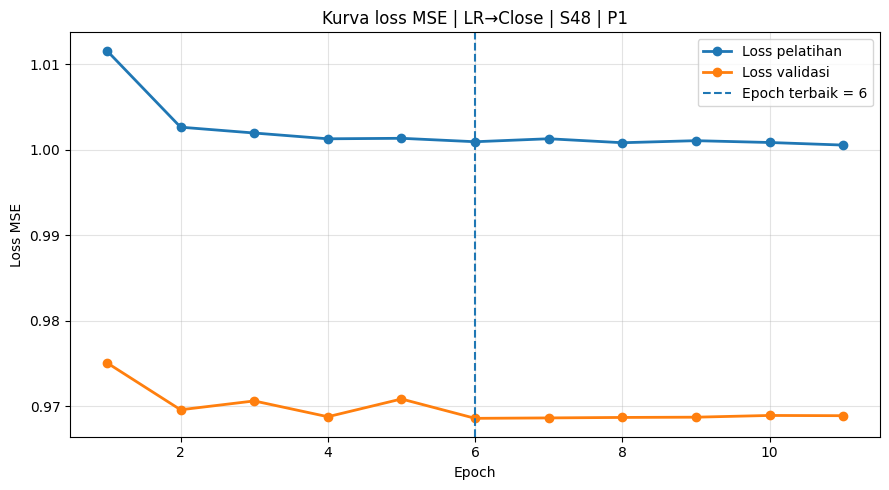

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq48_pred1.png | best_val_loss=0.96858187


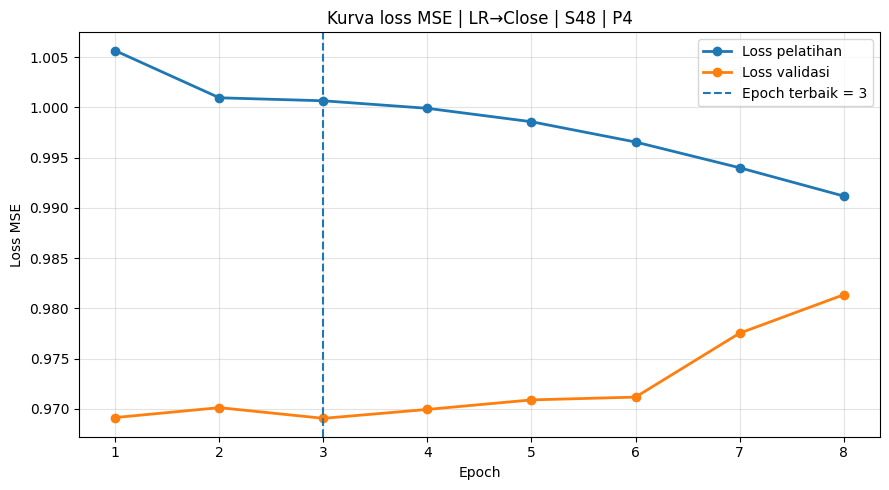

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq48_pred4.png | best_val_loss=0.96907062


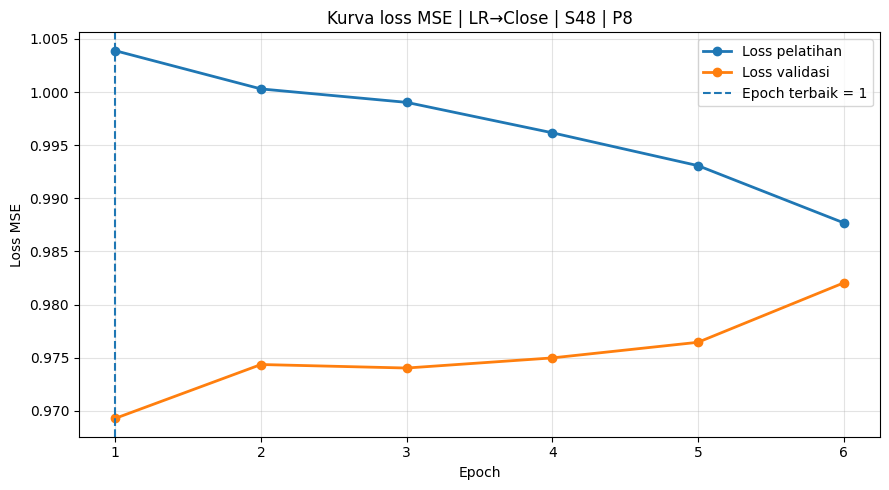

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq48_pred8.png | best_val_loss=0.96929318


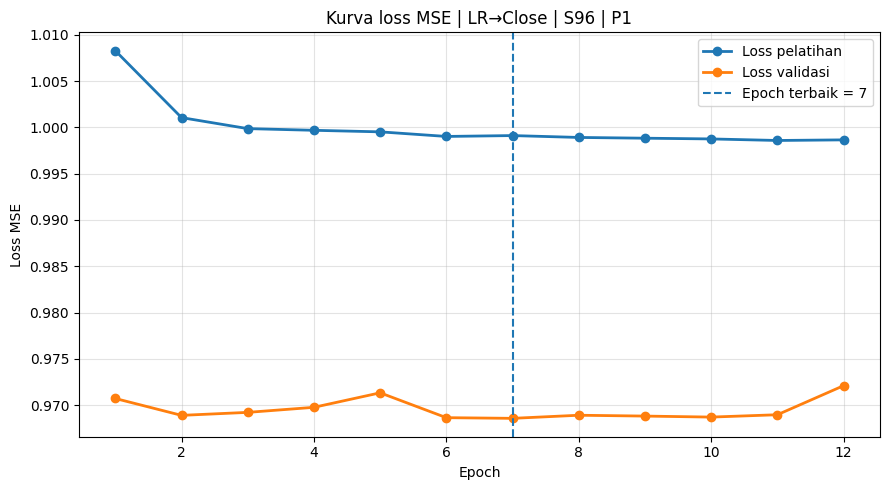

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq96_pred1.png | best_val_loss=0.96856902


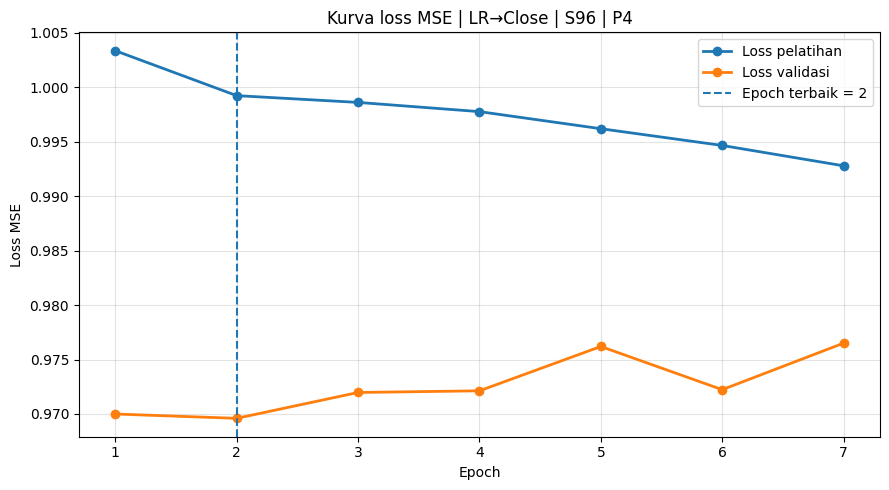

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq96_pred4.png | best_val_loss=0.96959766


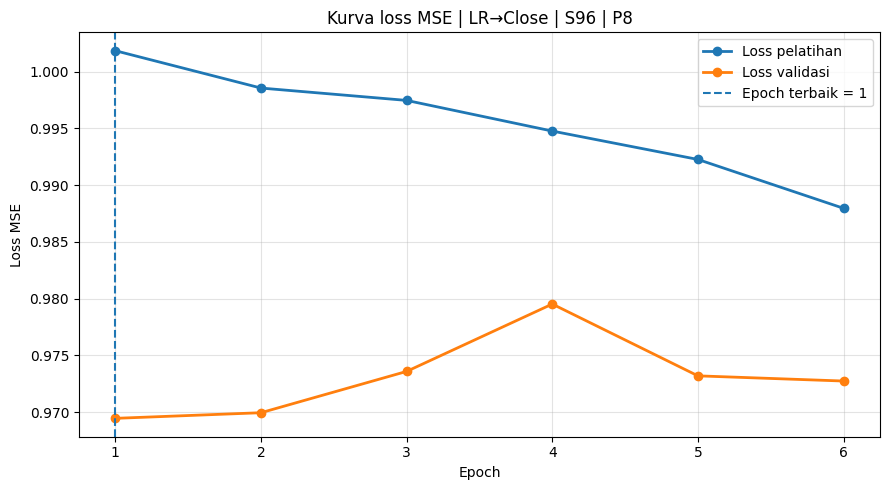

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq96_pred8.png | best_val_loss=0.96944254


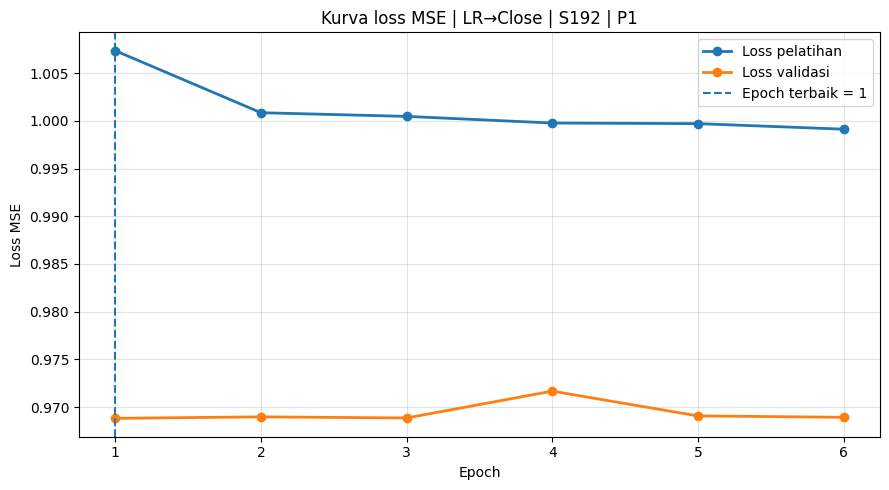

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq192_pred1.png | best_val_loss=0.96881791


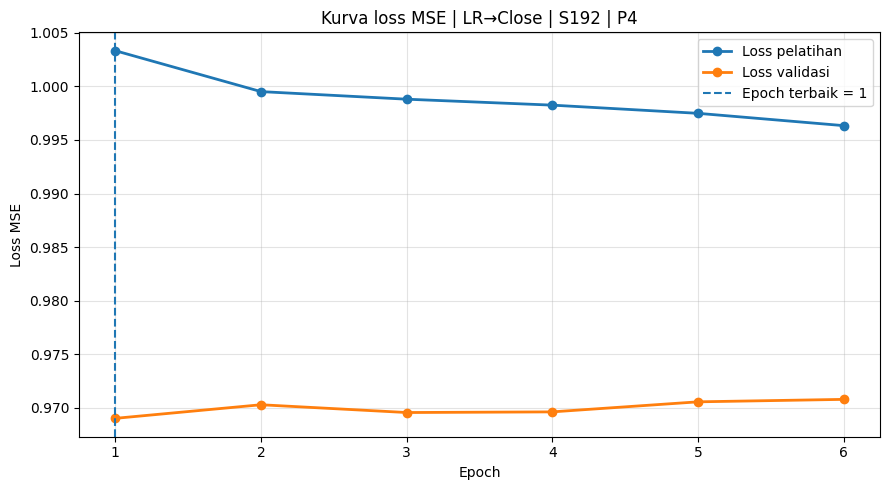

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq192_pred4.png | best_val_loss=0.96902676


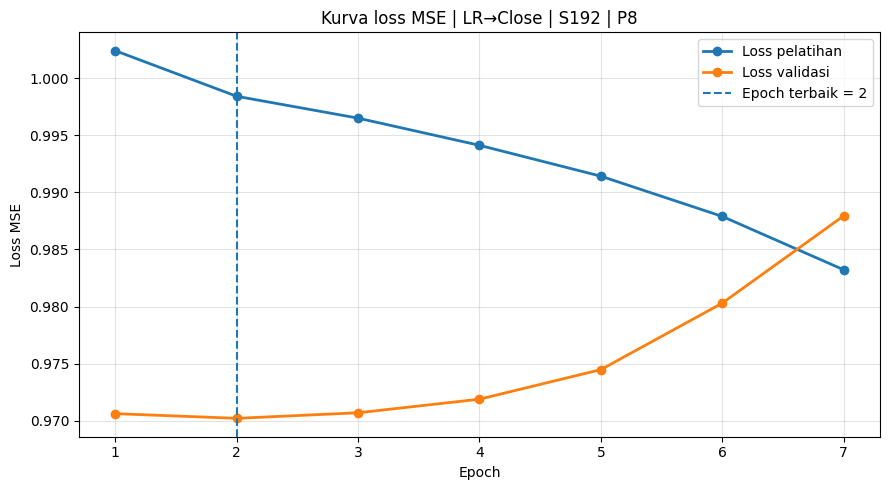

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq192_pred8.png | best_val_loss=0.97021806


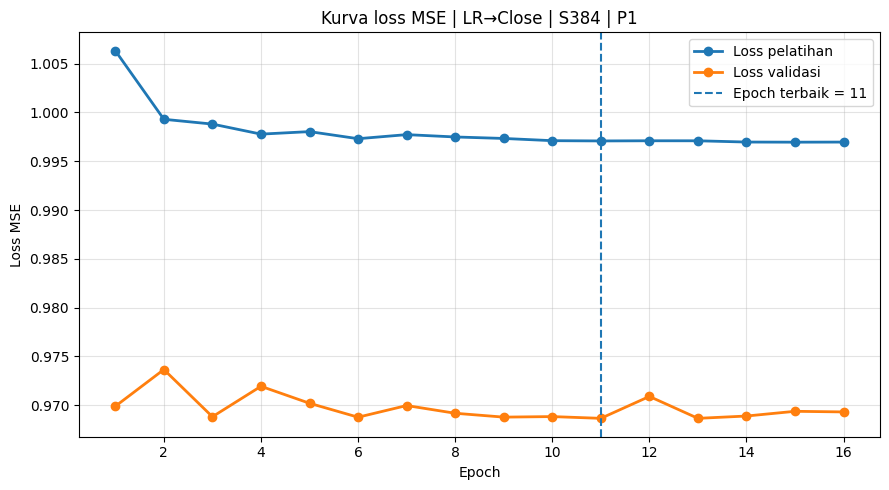

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq384_pred1.png | best_val_loss=0.96864449


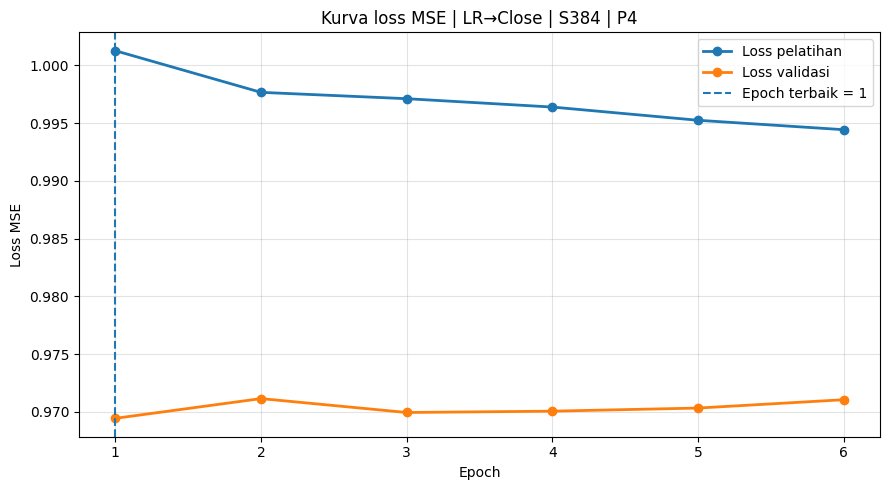

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq384_pred4.png | best_val_loss=0.96943409


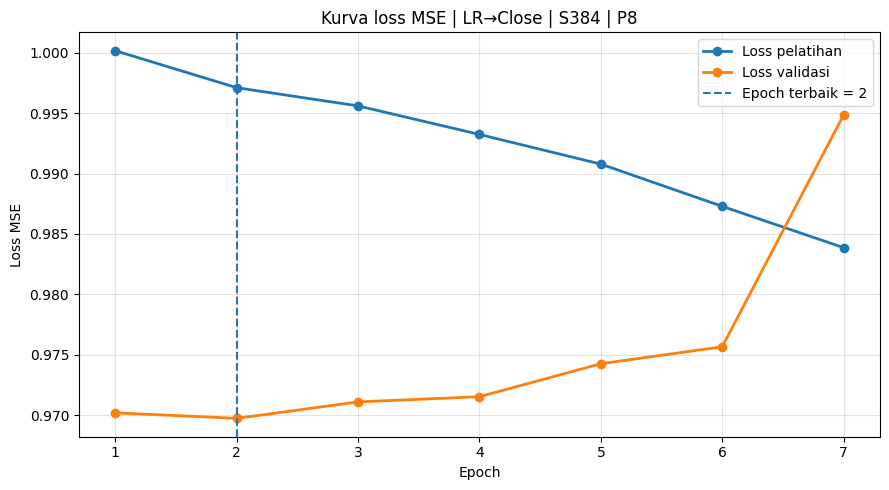

Tersimpan: /content/informer_comparison_plots/loss_mse_lr_to_close_seq384_pred8.png | best_val_loss=0.96973654


In [ ]:
# =========================
# 9. Plot loss per skenario
# =========================

loss_df = pd.read_csv(LOSS_HISTORY_CSV_PATH)
loss_df = loss_df.sort_values(["target_mode", "seq_len", "epoch"]).copy()

for _, scenario_group in loss_df.groupby(["target_mode", "seq_len", "pred_len"], sort=True):
    scenario_group = scenario_group.sort_values("epoch")
    target_mode = scenario_group["target_mode"].iloc[0]
    seq_len = int(scenario_group["seq_len"].iloc[0])
    pred_len = int(scenario_group["pred_len"].iloc[0])
    label = "LR→Close" if target_mode == "log_return_to_close" else "Close"
    scenario_name = f"{label} | S{seq_len} | P{pred_len}"

    best_idx = scenario_group["val_loss"].idxmin()
    best_epoch = int(scenario_group.loc[best_idx, "epoch"])
    best_val = float(scenario_group.loc[best_idx, "val_loss"])

    plt.figure(figsize=(9, 5))
    plt.plot(scenario_group["epoch"], scenario_group["train_loss"], marker="o", linewidth=2, label="Loss pelatihan")
    plt.plot(scenario_group["epoch"], scenario_group["val_loss"], marker="o", linewidth=2, label="Loss validasi")
    plt.axvline(best_epoch, linestyle="--", linewidth=1.5, label=f"Epoch terbaik = {best_epoch}")
    plt.title(f"Kurva loss MSE | {scenario_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss MSE")
    plt.grid(True, alpha=0.35)
    plt.legend()
    plt.tight_layout()

    safe_target = "lr_to_close" if target_mode == "log_return_to_close" else "close"
    path = f"{PLOT_OUTPUT_DIR}/loss_mse_{safe_target}_seq{seq_len}_pred{pred_len}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Tersimpan: {path} | best_val_loss={best_val:.8f}")


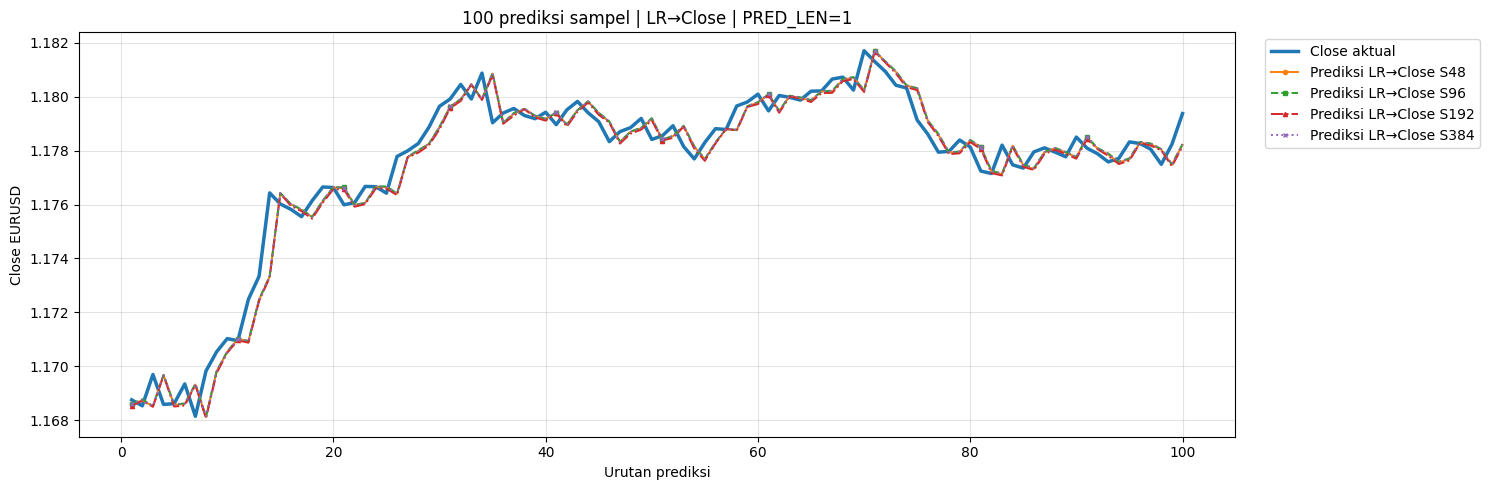

Tersimpan: /content/informer_comparison_plots/sample_predictions_100_lr_to_close_pred1_horizon1.png


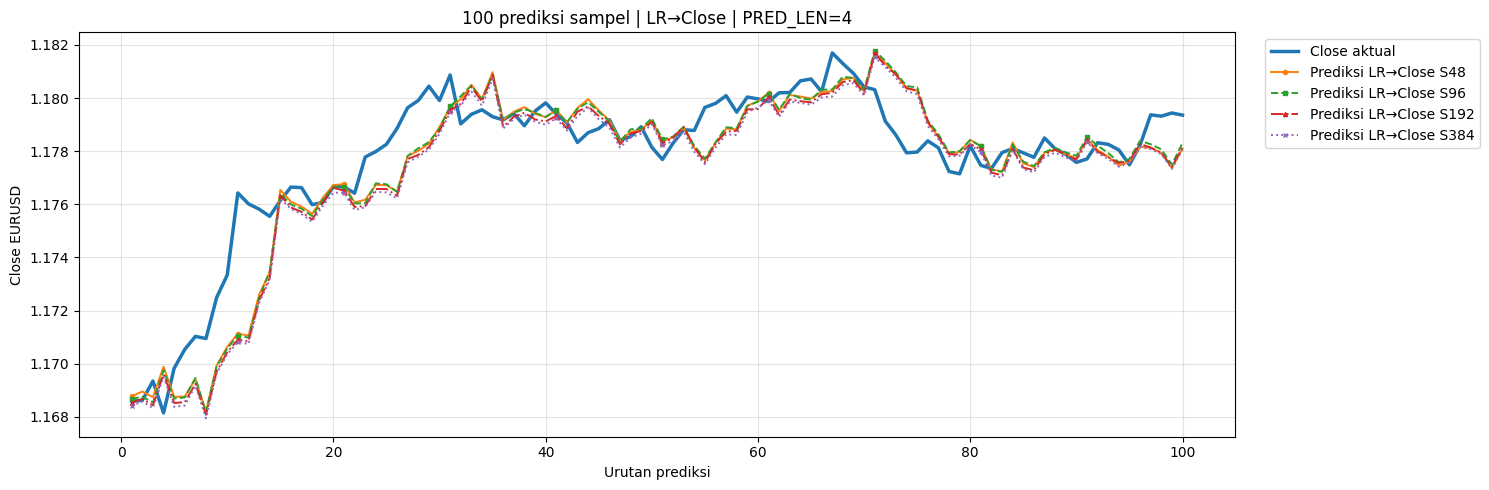

Tersimpan: /content/informer_comparison_plots/sample_predictions_100_lr_to_close_pred4_horizon4.png


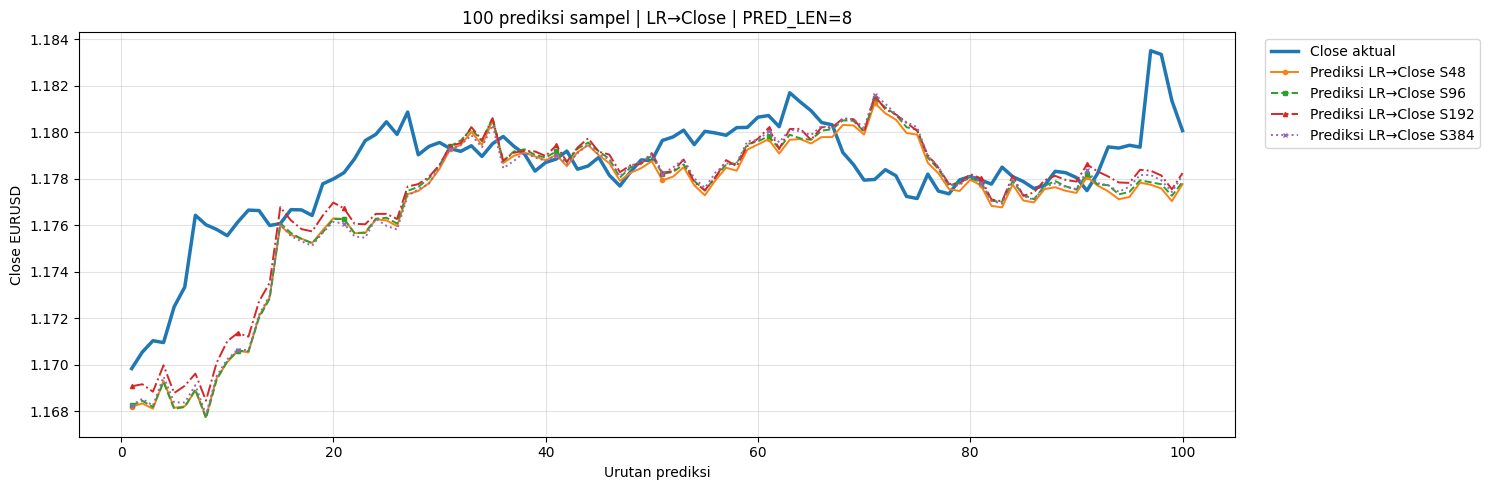

Tersimpan: /content/informer_comparison_plots/sample_predictions_100_lr_to_close_pred8_horizon8.png


In [ ]:
# =========================
# 10. Plot seluruh 100 prediksi pada sampel
# =========================

pred_df = pd.read_csv(PREDICTIONS_CSV_PATH, parse_dates=["date"])


def marker_for_seq(seq_len):
    return {48: "o", 96: "s", 192: "^", 384: "x"}.get(int(seq_len), None)


def linestyle_for_seq(seq_len):
    return {48: "-", 96: "--", 192: "-.", 384: ":"}.get(int(seq_len), "-")


# Untuk skenario multi-step, plot yang ditampilkan adalah horizon terakhir dari setiap titik awal prediksi:
# PRED_LEN=4 menggunakan forecast_step=4, sedangkan PRED_LEN=8 menggunakan forecast_step=8.
for pred_len in PRED_LENS:
    temp = pred_df[(pred_df["pred_len"] == pred_len) & (pred_df["forecast_step"] == pred_len)].copy()
    if temp.empty:
        continue

    actual = temp.groupby("prediction_order", as_index=False)["true_close"].mean()

    plt.figure(figsize=(15, 5))
    plt.plot(actual["prediction_order"], actual["true_close"], linewidth=2.5, label="Close aktual")
    for seq_len, group in temp.groupby("seq_len"):
        group = group.sort_values("prediction_order")
        plt.plot(
            group["prediction_order"], group["pred_close"],
            linestyle=linestyle_for_seq(seq_len), marker=marker_for_seq(seq_len), markevery=10,
            linewidth=1.4, markersize=3, label=f"Prediksi LR→Close S{seq_len}"
        )
    plt.title(f"100 prediksi sampel | LR→Close | PRED_LEN={pred_len}")
    plt.xlabel("Urutan prediksi")
    plt.ylabel("Close EURUSD")
    plt.grid(True, alpha=0.35)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    path = f"{PLOT_OUTPUT_DIR}/sample_predictions_100_lr_to_close_pred{pred_len}_horizon{pred_len}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Tersimpan:", path)


,window,label_jendela,start_prediction_order,end_prediction_order
0,first_50,50 prediksi pertama,1,50
1,last_50,50 prediksi terakhir,51,100
2,first_20,20 prediksi pertama,1,20
3,middle_20,20 prediksi tengah,41,60
4,last_20,20 prediksi terakhir,81,100


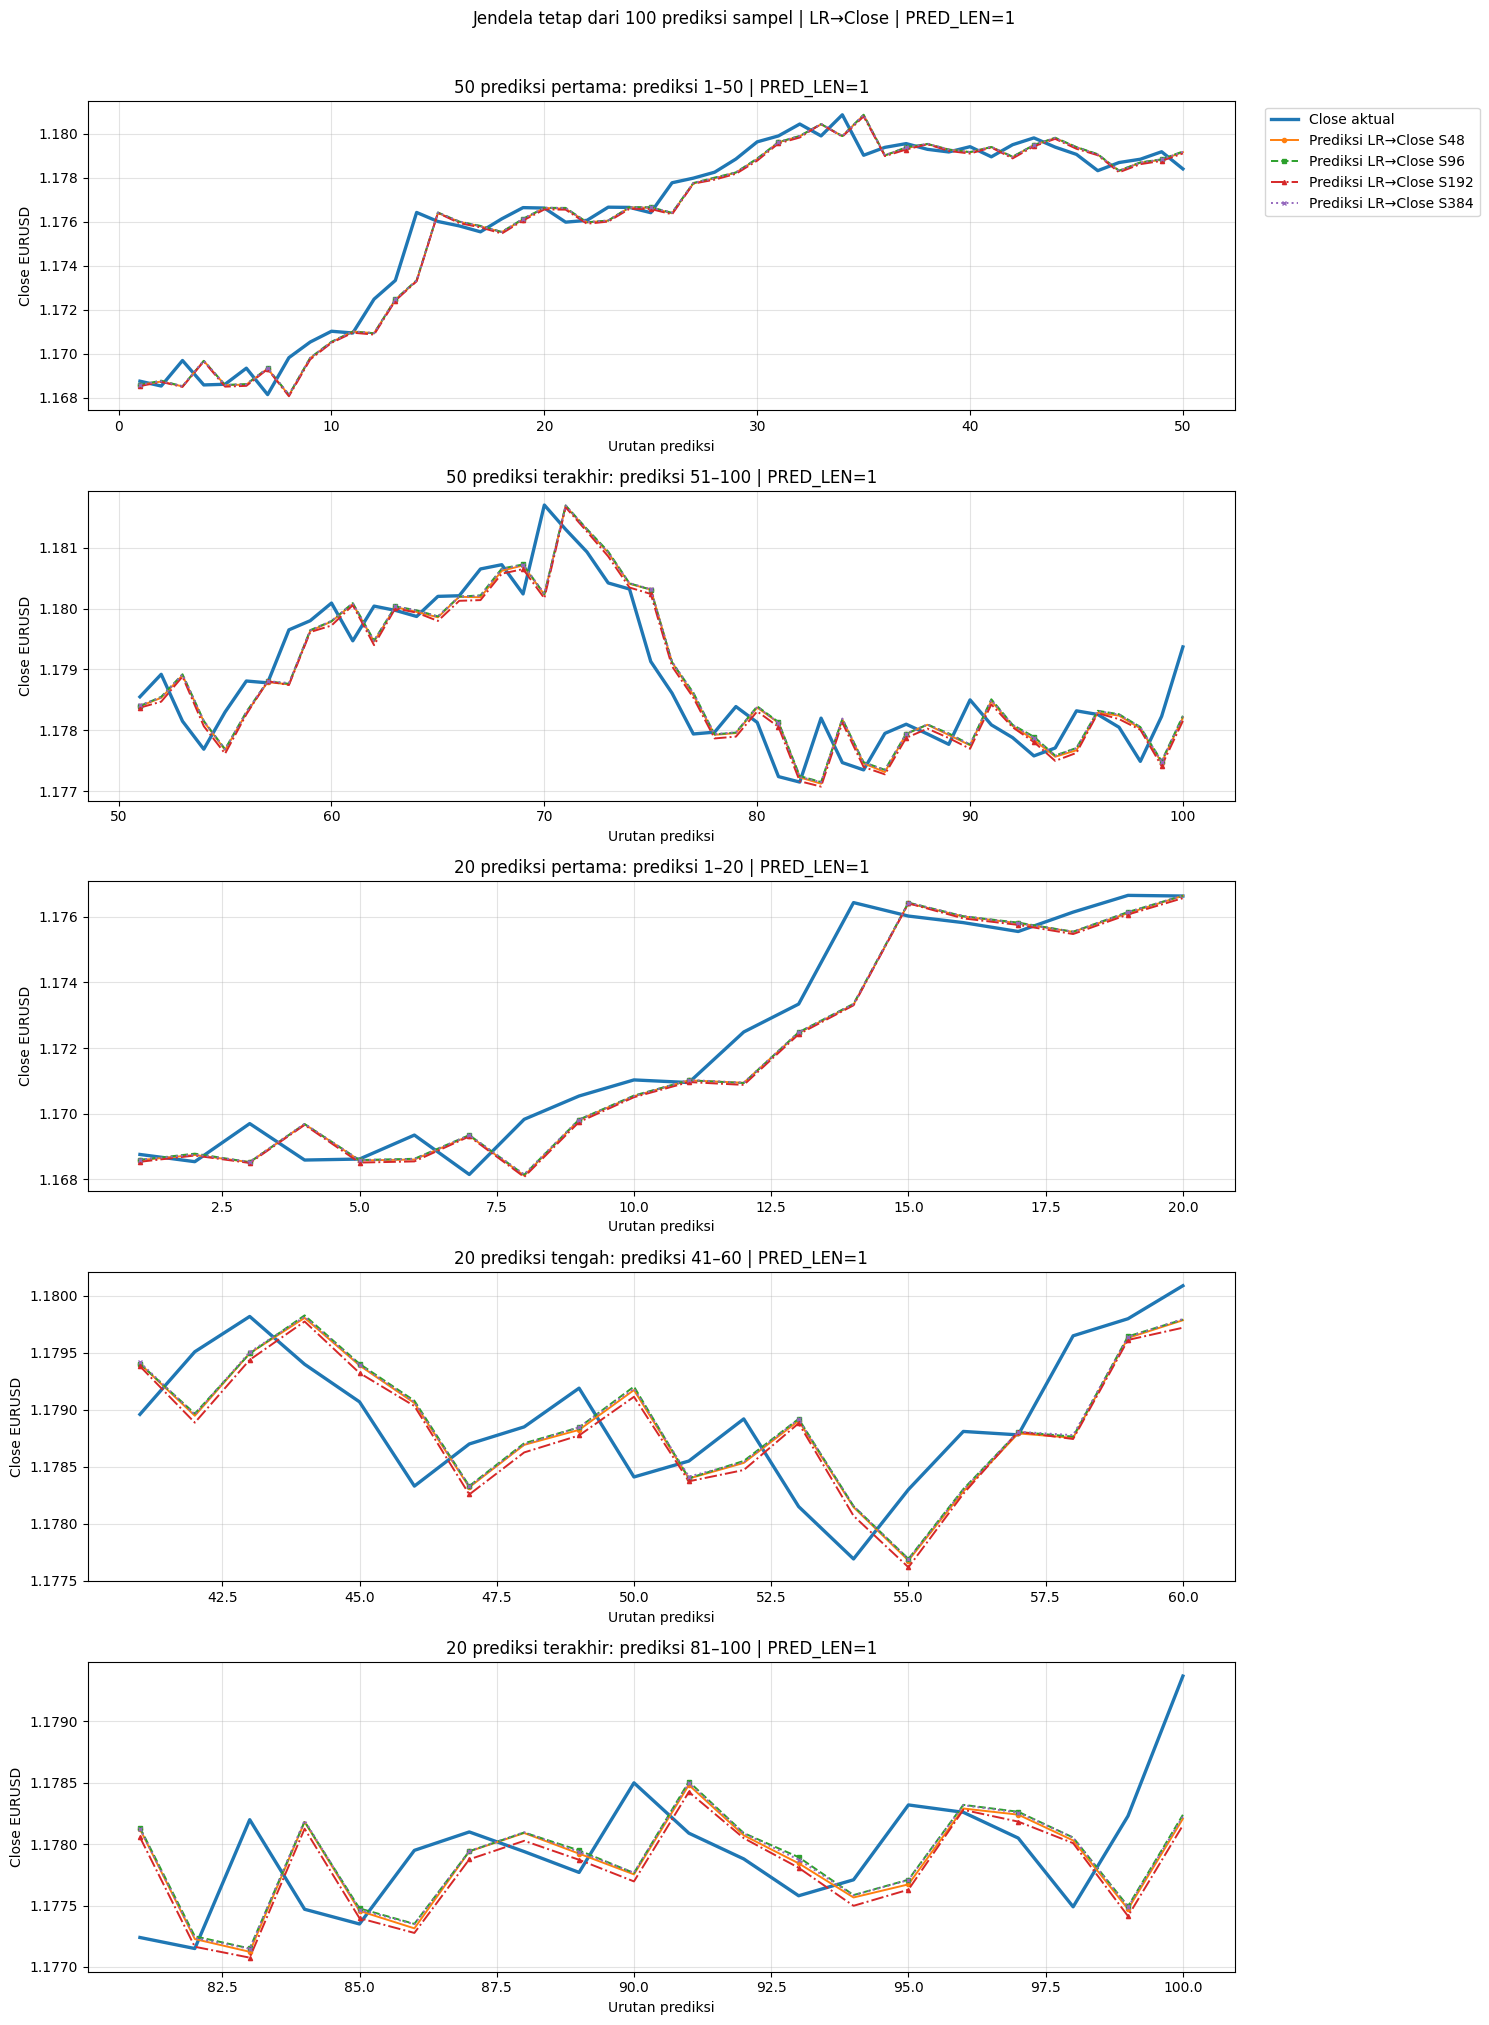

Tersimpan: /content/informer_comparison_plots/sample_prediction_windows_lr_to_close_pred1_horizon1.png


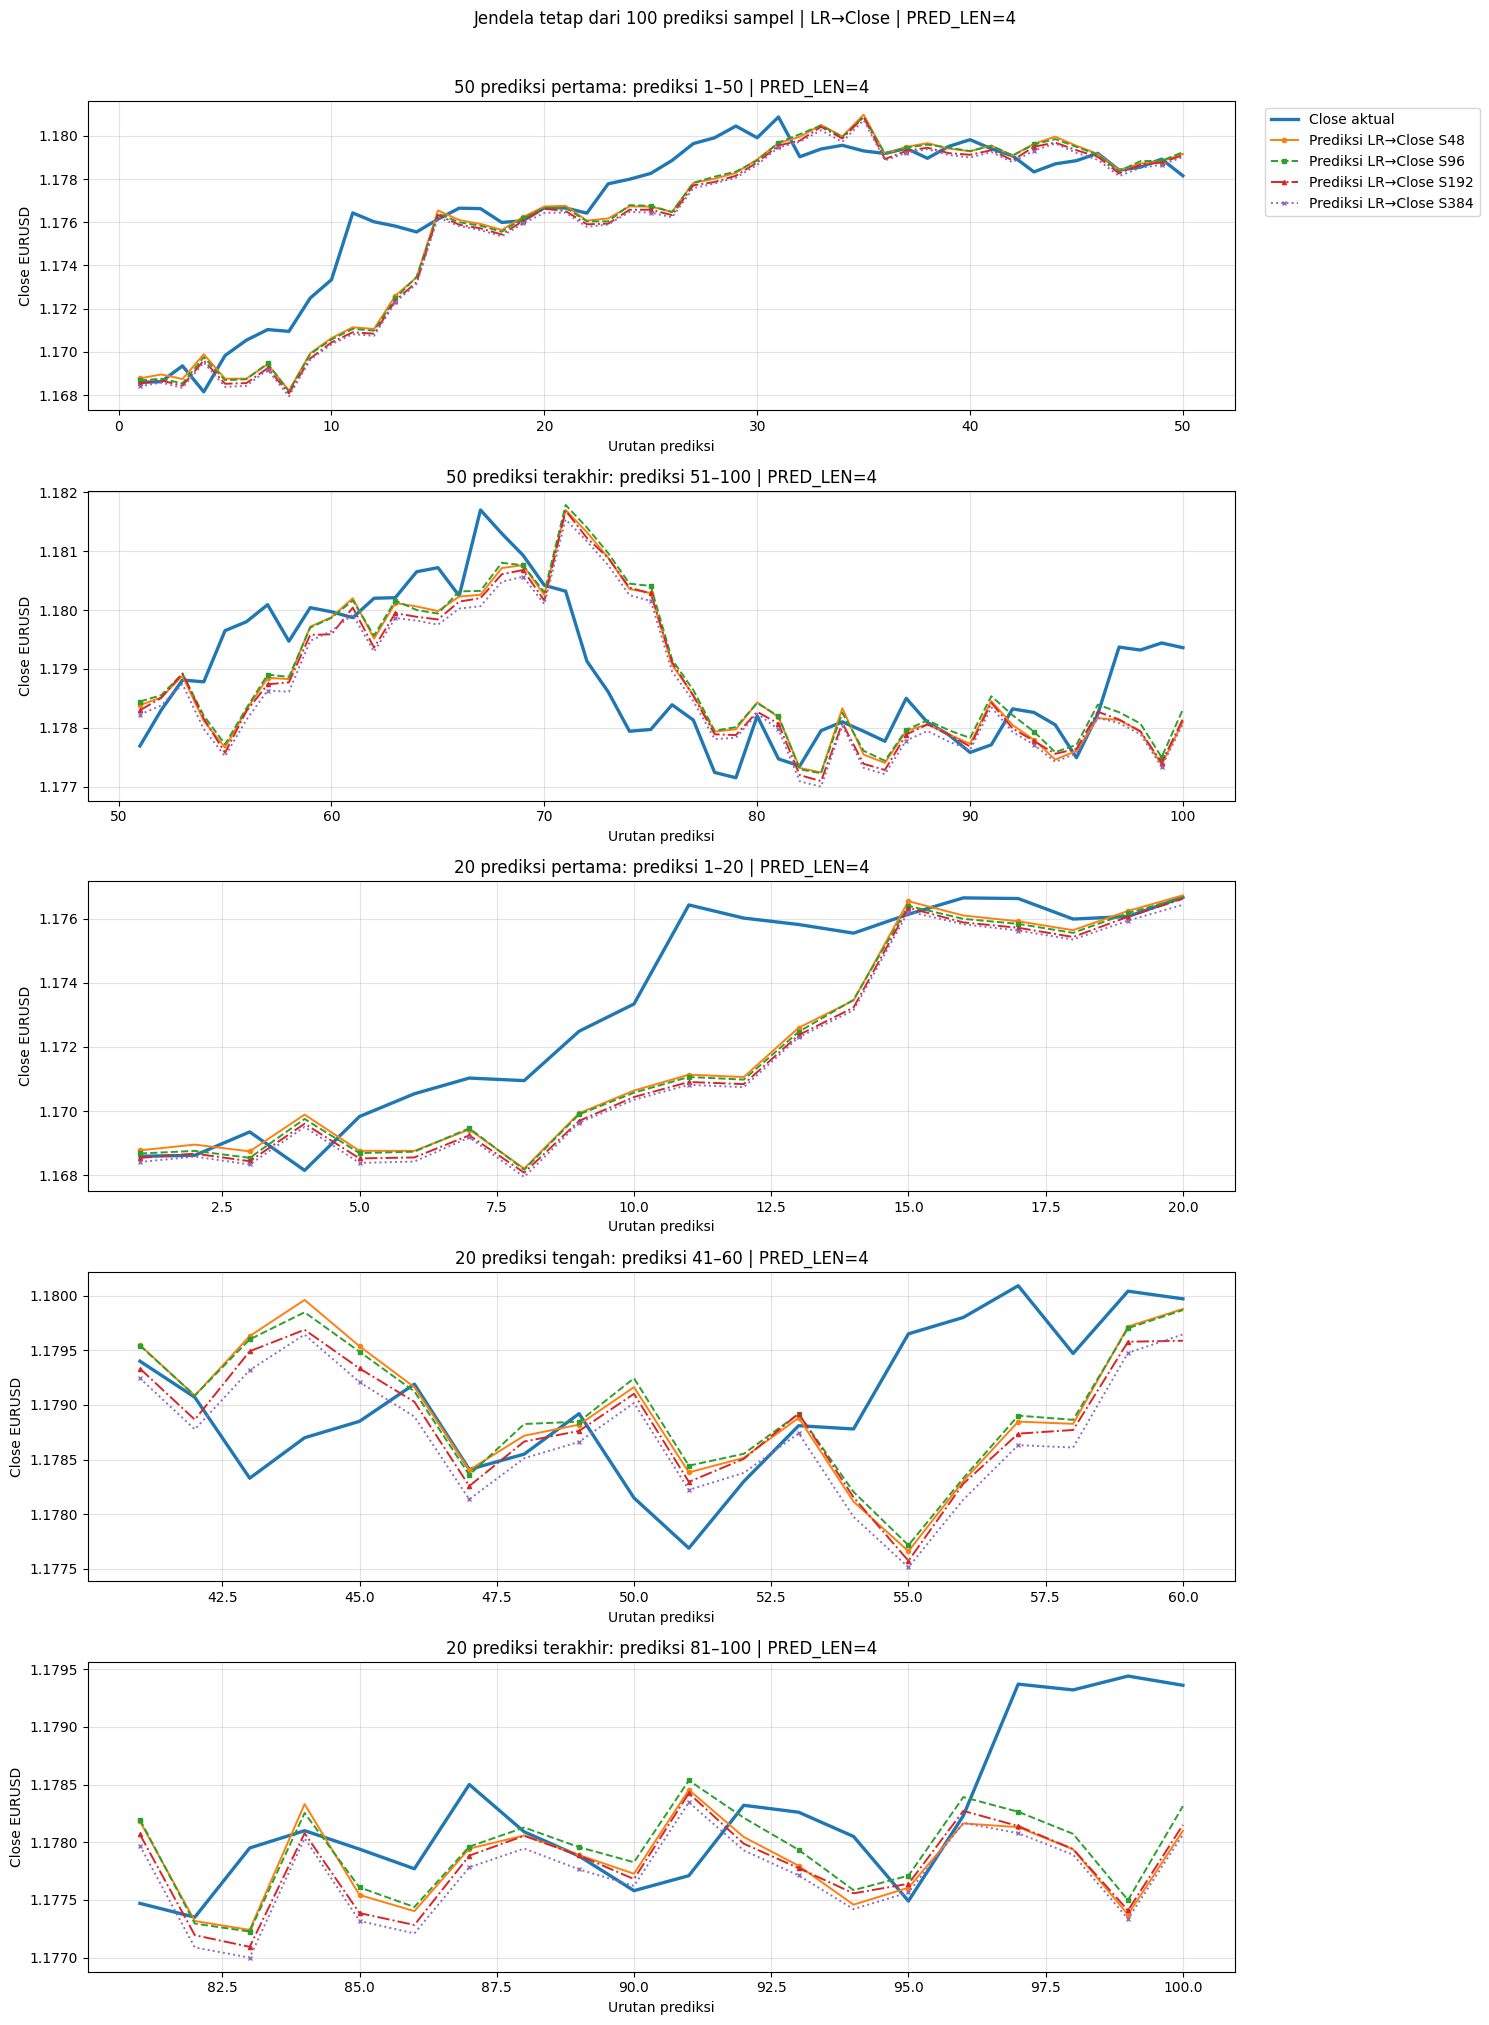

Tersimpan: /content/informer_comparison_plots/sample_prediction_windows_lr_to_close_pred4_horizon4.png


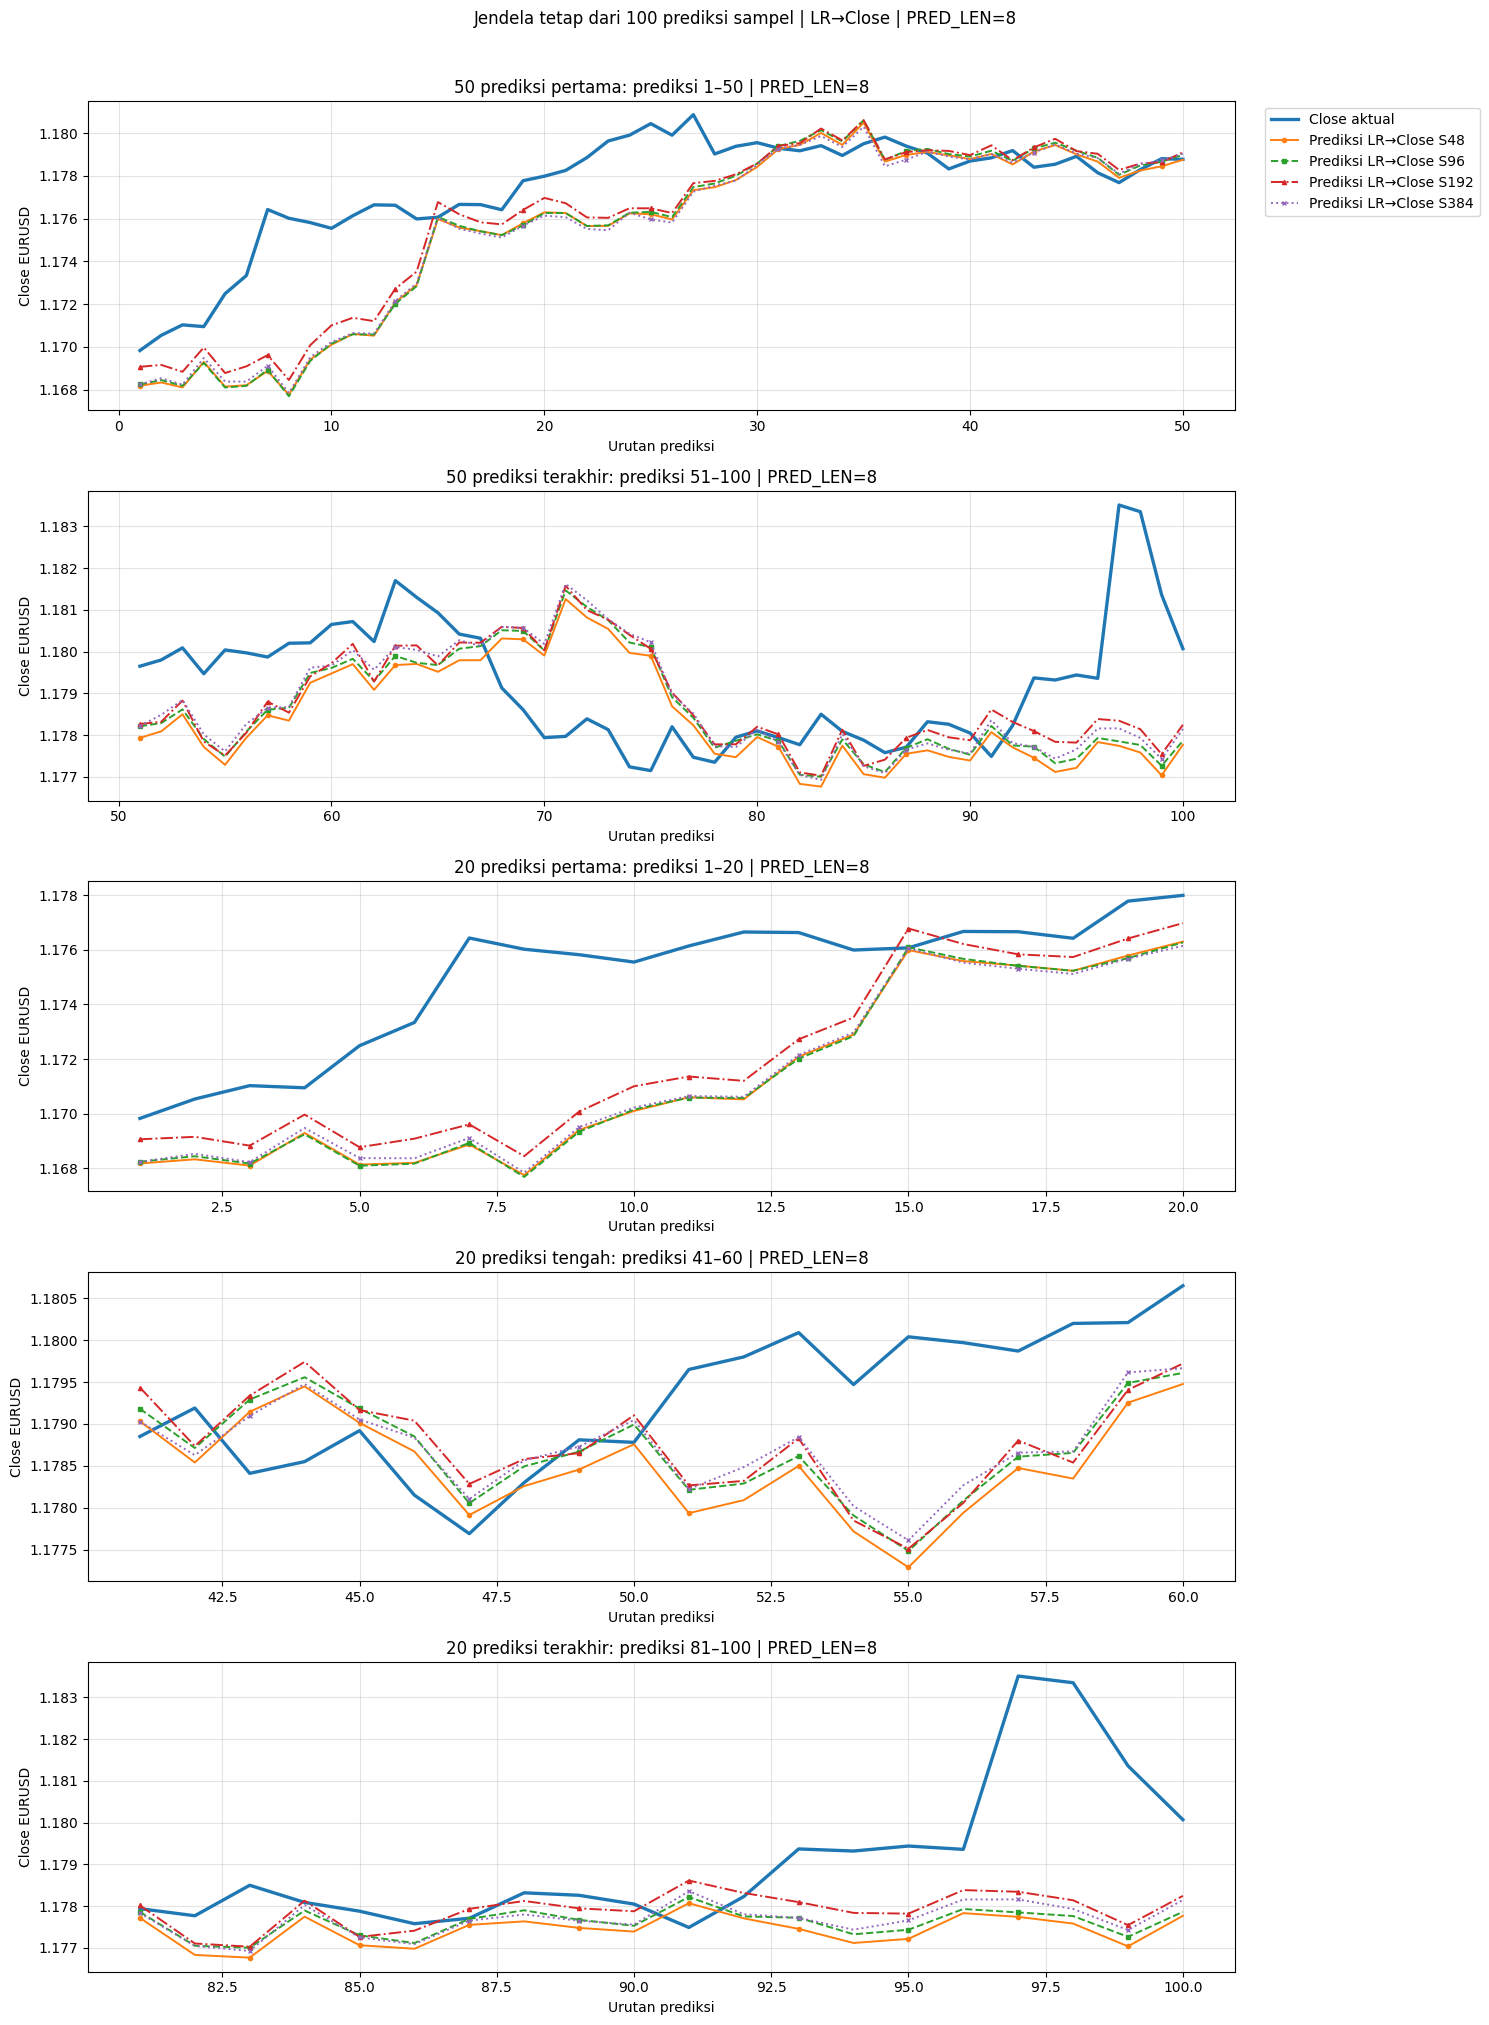

Tersimpan: /content/informer_comparison_plots/sample_prediction_windows_lr_to_close_pred8_horizon8.png


In [ ]:
# =========================
# 11. Plot Window: 50 pertama, 50 terakhir, 20 pertama, 20 tengah, 20 terakhir
# =========================

WINDOWS = {
    "first_50": (1, 50),
    "last_50": (SAMPLE_TARGET_PREDICTIONS - 49, SAMPLE_TARGET_PREDICTIONS),
    "first_20": (1, 20),
    "middle_20": ((SAMPLE_TARGET_PREDICTIONS - 20) // 2 + 1, (SAMPLE_TARGET_PREDICTIONS - 20) // 2 + 20),
    "last_20": (SAMPLE_TARGET_PREDICTIONS - 19, SAMPLE_TARGET_PREDICTIONS),
}

WINDOW_LABELS_ID = {
    "first_50": "50 prediksi pertama",
    "last_50": "50 prediksi terakhir",
    "first_20": "20 prediksi pertama",
    "middle_20": "20 prediksi tengah",
    "last_20": "20 prediksi terakhir",
}

window_summary = []
for name, (start, end) in WINDOWS.items():
    window_summary.append({"window": name, "label_jendela": WINDOW_LABELS_ID.get(name, name), "start_prediction_order": start, "end_prediction_order": end})
    pred_df[(pred_df["prediction_order"] >= start) & (pred_df["prediction_order"] <= end)].to_csv(
        f"{OUTPUT_DIR}/sample_predictions_{name}_all_pred_lens.csv", index=False
    )

pd.DataFrame(window_summary).to_csv(f"{OUTPUT_DIR}/sample_prediction_windows.csv", index=False)
display(pd.DataFrame(window_summary))

# Untuk PRED_LEN > 1, hanya horizon terakhir yang diplot agar grafik tetap mudah dibaca.
# Contoh: PRED_LEN=8 menampilkan forecast_step=8 dari setiap titik awal prediksi.
for pred_len in PRED_LENS:
    target_df = pred_df[(pred_df["pred_len"] == pred_len) & (pred_df["forecast_step"] == pred_len)].copy()
    if target_df.empty:
        continue

    fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(15, 4 * len(WINDOWS)), sharey=False)

    for ax, (name, (start, end)) in zip(axes, WINDOWS.items()):
        temp = target_df[(target_df["prediction_order"] >= start) & (target_df["prediction_order"] <= end)].copy()
        actual = temp.groupby("prediction_order", as_index=False)["true_close"].mean()
        ax.plot(actual["prediction_order"], actual["true_close"], linewidth=2.4, label="Close aktual")
        for seq_len, group in temp.groupby("seq_len"):
            group = group.sort_values("prediction_order")
            ax.plot(
                group["prediction_order"], group["pred_close"],
                linestyle=linestyle_for_seq(seq_len), marker=marker_for_seq(seq_len), markevery=max(1, len(group)//8),
                linewidth=1.4, markersize=3, label=f"Prediksi LR→Close S{seq_len}"
            )
        ax.set_title(f"{WINDOW_LABELS_ID.get(name, name)}: prediksi {start}–{end} | PRED_LEN={pred_len}")
        ax.set_xlabel("Urutan prediksi")
        ax.set_ylabel("Close EURUSD")
        ax.grid(True, alpha=0.35)
        if name == "first_50":
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

    fig.suptitle(f"Jendela tetap dari 100 prediksi sampel | LR→Close | PRED_LEN={pred_len}", y=1.01)
    plt.tight_layout()
    path = f"{PLOT_OUTPUT_DIR}/sample_prediction_windows_lr_to_close_pred{pred_len}_horizon{pred_len}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Tersimpan:", path)


Tabel metrik skripsi tersimpan: /content/informer_outputs/informer_thesis_metric_table_mse_lr_to_close_predlen_1_4_8_100pred.csv


,scenario_label,target_mode,features,loss_function,seq_len,label_len,pred_len,best_epoch,epochs_ran,best_val_loss,test_close_MAE,test_close_MSE,test_close_MAPE_percent,sample_close_MAE,sample_close_MSE,sample_close_MAPE_percent
9,LR→Close | S384 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,384,192,1,11,16,0.968644,0.000654,0.000001,0.058907,0.000514,4.820062e-07,0.043712
3,LR→Close | S96 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,96,48,1,7,12,0.968569,0.000654,0.000001,0.058924,0.000516,4.835157e-07,0.043848
0,LR→Close | S48 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,48,24,1,6,11,0.968582,0.000654,0.000001,0.058935,0.000516,4.869881e-07,0.043851
6,LR→Close | S192 | P1,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,192,96,1,1,6,0.968818,0.000656,0.000001,0.059088,0.000526,5.027611e-07,0.044675
4,LR→Close | S96 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,96,48,4,2,7,0.969598,0.001028,0.000003,0.092676,0.000758,1.157653e-06,0.064419
1,LR→Close | S48 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,48,24,4,3,8,0.969071,0.001028,0.000003,0.092669,0.000761,1.150587e-06,0.064609
7,LR→Close | S192 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,192,96,4,1,6,0.969027,0.001028,0.000003,0.092699,0.000781,1.227392e-06,0.066369
10,LR→Close | S384 | P4,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,384,192,4,1,6,0.969434,0.001031,0.000003,0.092909,0.000797,1.271022e-06,0.067728
8,LR→Close | S192 | P8,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,192,96,8,2,7,0.970218,0.001396,0.000005,0.125848,0.001096,2.654738e-06,0.093048
11,LR→Close | S384 | P8,log_return_to_close,"Open,High,Low,Close,Volume,log_return,RSI_14,A...",mse,384,192,8,2,7,0.969737,0.001396,0.000005,0.125843,0.001164,3.075895e-06,0.098837


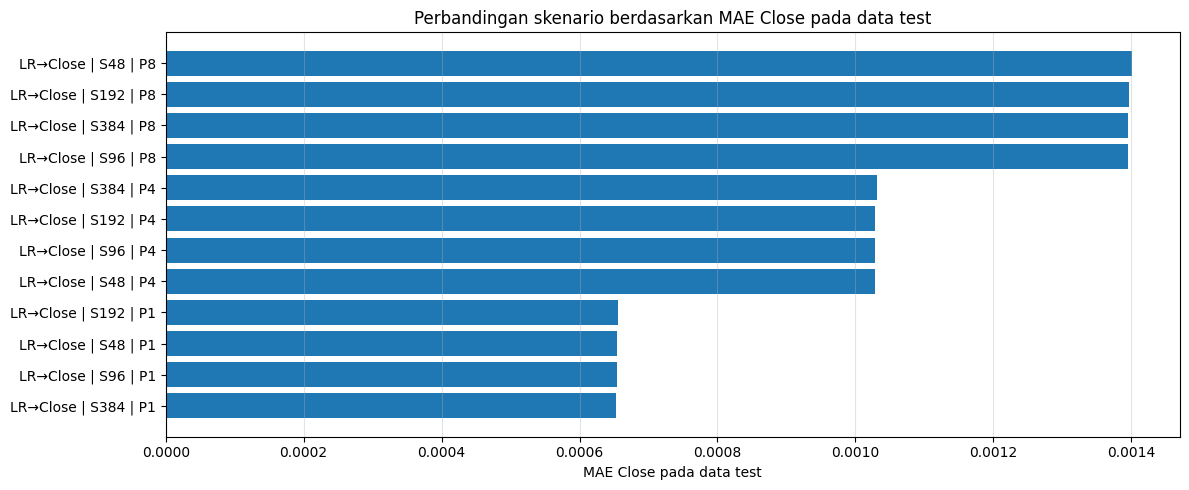

Tersimpan: /content/informer_comparison_plots/metric_test_close_MAE.png


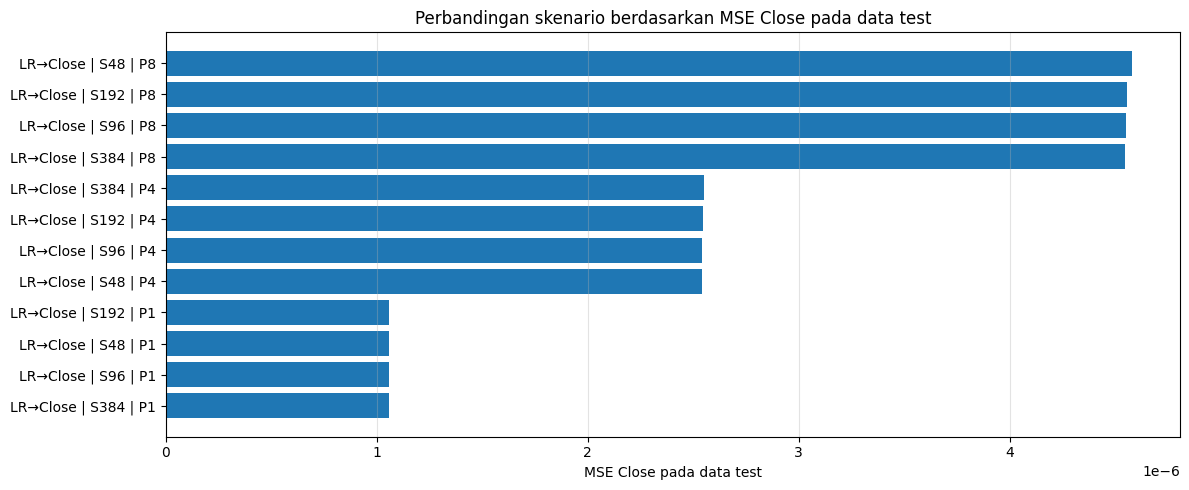

Tersimpan: /content/informer_comparison_plots/metric_test_close_MSE.png


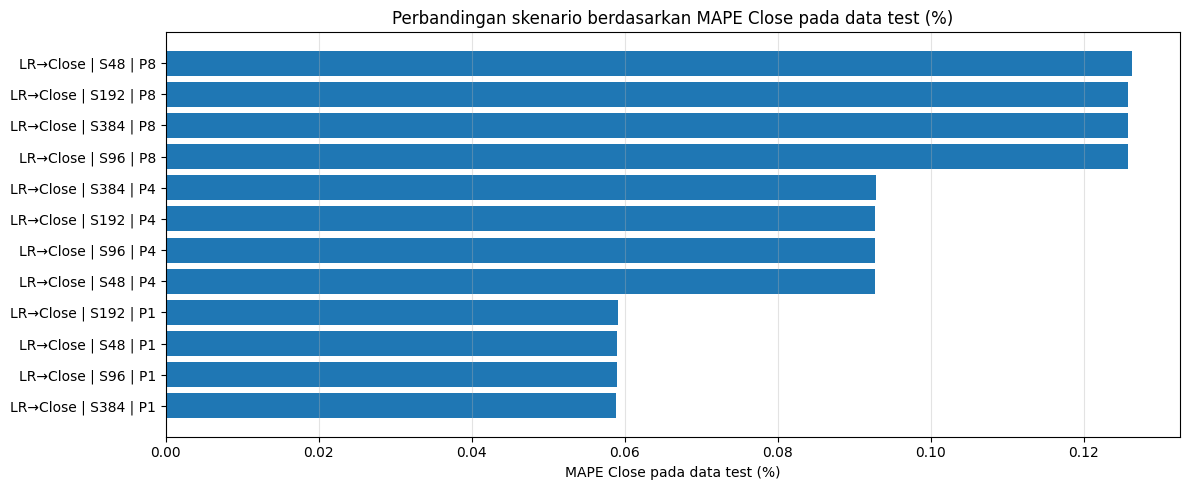

Tersimpan: /content/informer_comparison_plots/metric_test_close_MAPE_percent.png


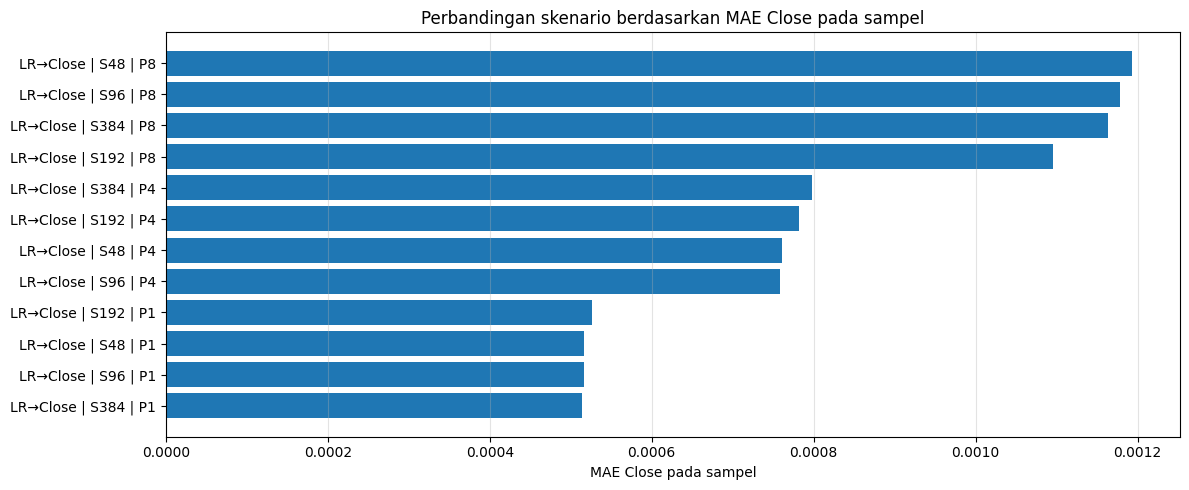

Tersimpan: /content/informer_comparison_plots/metric_sample_close_MAE.png


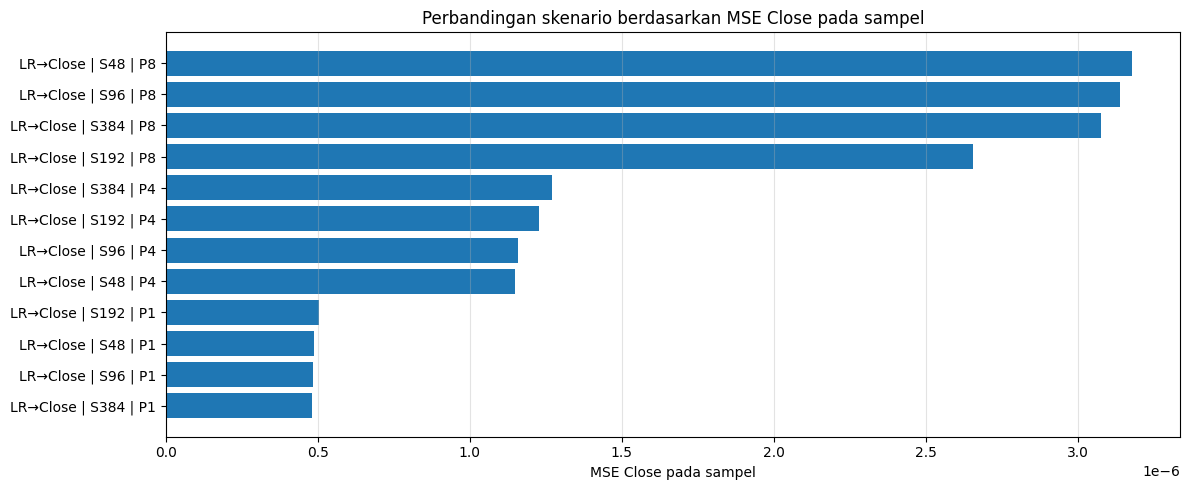

Tersimpan: /content/informer_comparison_plots/metric_sample_close_MSE.png


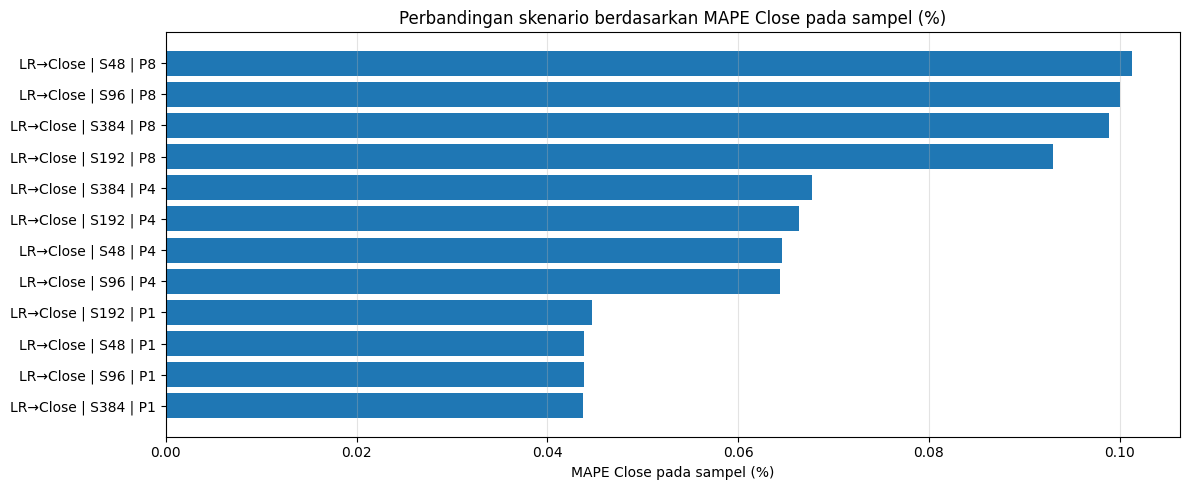

Tersimpan: /content/informer_comparison_plots/metric_sample_close_MAPE_percent.png


In [ ]:
# =========================
# 12. Tabel metrik
# =========================

results_df = pd.read_csv(RESULTS_CSV_PATH)

METRIC_LABELS_ID = {
    "test_close_MAE": "MAE Close pada data test",
    "test_close_MSE": "MSE Close pada data test",
    "test_close_MAPE_percent": "MAPE Close pada data test (%)",
    "sample_close_MAE": "MAE Close pada sampel",
    "sample_close_MSE": "MSE Close pada sampel",
    "sample_close_MAPE_percent": "MAPE Close pada sampel (%)",
}

metric_cols = [
    "scenario_label", "target_mode", "features", "loss_function", "seq_len", "label_len", "pred_len",
    "best_epoch", "epochs_ran", "best_val_loss",
    "test_close_MAE", "test_close_MSE", "test_close_MAPE_percent",
    "sample_close_MAE", "sample_close_MSE", "sample_close_MAPE_percent",
]
metric_cols = [c for c in metric_cols if c in results_df.columns]
metric_table = results_df[metric_cols].copy()

# Urutkan tabel berdasarkan MAPE pada data sampel karena MAPE paling mudah diinterpretasikan dalam persentase.
if "sample_close_MAPE_percent" in metric_table.columns:
    metric_table = metric_table.sort_values("sample_close_MAPE_percent")

metric_table.to_csv(METRIC_TABLE_PATH, index=False)
print("Tabel metrik skripsi tersimpan:", METRIC_TABLE_PATH)
display(metric_table)

# Grafik perbandingan skenario menggunakan metrik regresi: MAE, MSE, dan MAPE.
metric_plot_cols = [
    "test_close_MAE", "test_close_MSE", "test_close_MAPE_percent",
    "sample_close_MAE", "sample_close_MSE", "sample_close_MAPE_percent",
]

for metric in metric_plot_cols:
    if metric not in results_df.columns:
        continue
    temp = results_df.dropna(subset=[metric]).sort_values(metric, ascending=True)
    plt.figure(figsize=(12, 5))
    plt.barh(temp["scenario_label"], temp[metric])
    plt.title(f"Perbandingan skenario berdasarkan {METRIC_LABELS_ID.get(metric, metric)}")
    plt.xlabel(METRIC_LABELS_ID.get(metric, metric))
    plt.grid(axis="x", alpha=0.35)
    plt.tight_layout()
    path = f"{PLOT_OUTPUT_DIR}/metric_{metric}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Tersimpan:", path)
